SIMULACIÓN CON 20 ÓRBITAS

365.69735885301816


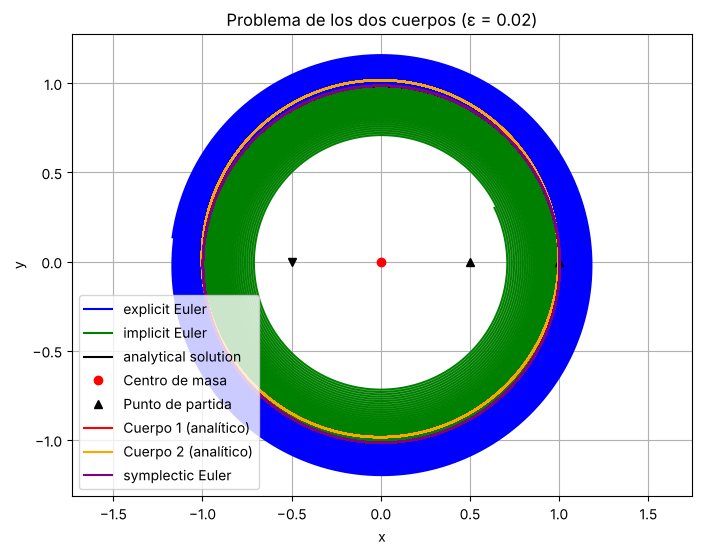

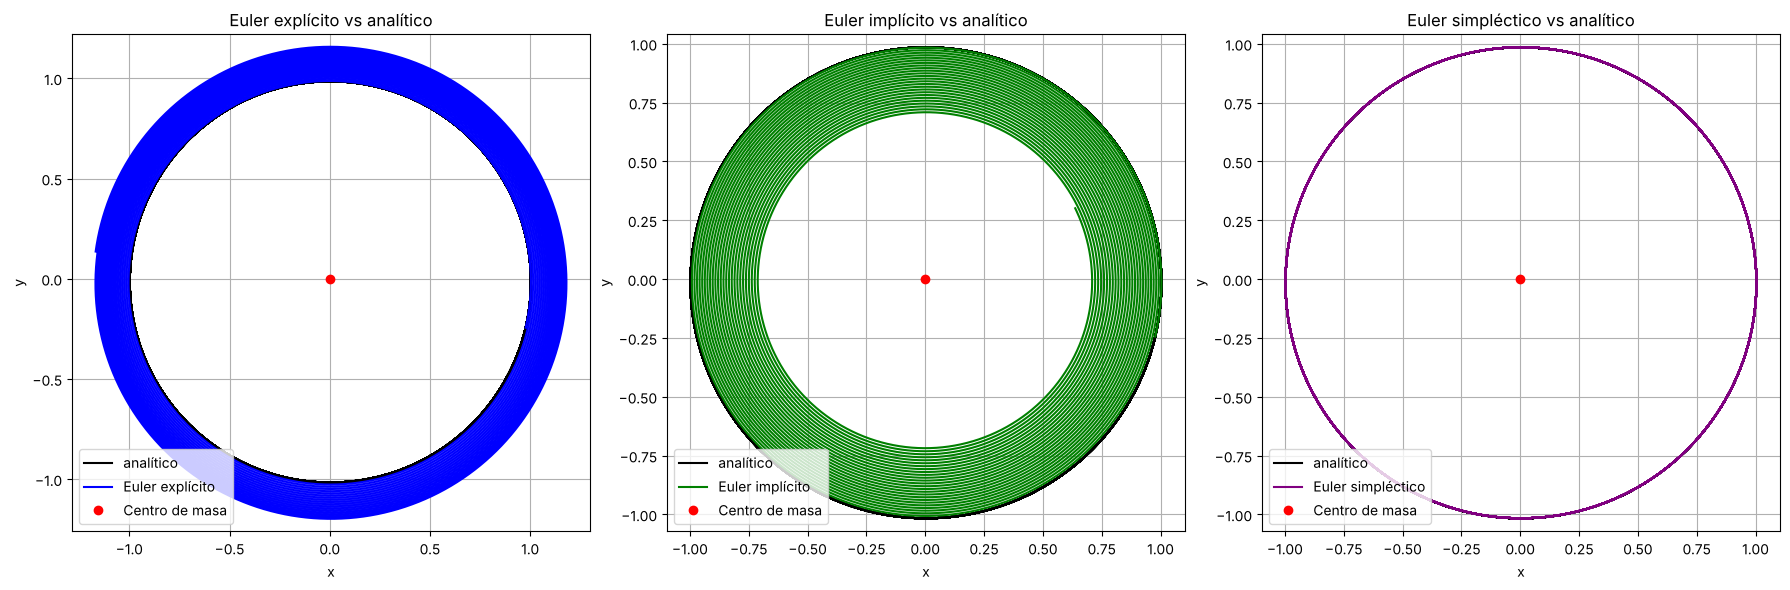

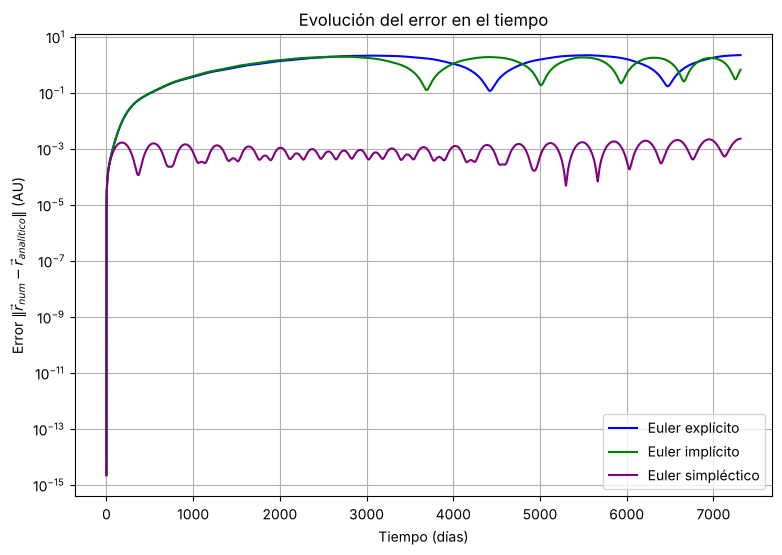

Órbita               Explícito (min/máx)             Implícito (min/máx)           Simpléctico (min/máx)
1             2.222e-15        5.275e-02      2.222e-15        5.363e-02      2.222e-15        1.653e-03
2             5.276e-02        2.018e-01      5.364e-02        2.107e-01      1.130e-04        1.538e-03
3             2.018e-01        4.421e-01      2.107e-01        4.732e-01      2.250e-04        1.423e-03
4             4.421e-01        7.609e-01      4.732e-01        8.319e-01      3.037e-04        1.309e-03
5             7.610e-01        1.134e+00      8.319e-01        1.253e+00      3.534e-04        1.194e-03
6             1.134e+00        1.520e+00      1.253e+00        1.656e+00      3.856e-04        1.079e-03
7             1.520e+00        1.857e+00      1.656e+00        1.901e+00      4.045e-04        9.647e-04
8             1.857e+00        2.061e+00      1.804e+00        1.912e+00      4.121e-04        9.044e-04
9             2.036e+00        2.088e+00      1.216e+00

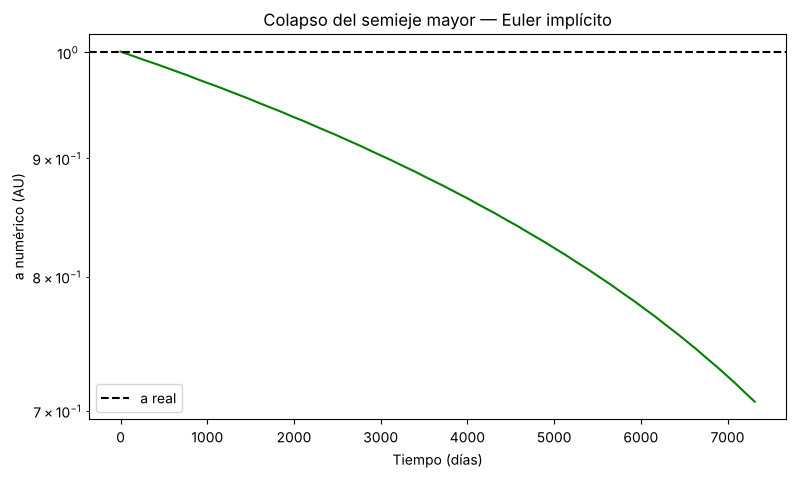

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton, root

#cantidad de orbitas

n_orbitas = 20

#pasos a considerar, notese que entre mayor el paso mejor se notan los cambios,
#en cambio, si usamos pasos muy cortos se extiende el tiempo de compilacion
delta_t = 0.05

# --- Parameters and initial conditions / Parámetros y condiciones iniciales---
G = 2.95912208286e-4   # gravitational constant / constante gravitacional
m1 = 1.0       # masa del sol relativa
m2 = 3.00348959632e-6 # mass de la tierra relativa
M = m1 + m2 # Total mass / Masa total
mu = (m1 * m2) / M

# Start at perihelion on the x-axis / Inicio en el perihelio en el eje x
r0 = np.array([9.773607012272747e-01,-2.440933024736090e-01]) # Initial position / Position initala
v_kreis = np.sqrt(G * M / np.linalg.norm(r0)) # velocity for a circle / velocidad para un circulo
# For a flatter ellipse, use e.g., 1.35 / Para una elipse más plana, usa p.ej. 1.35
v0 = np.array([3.894601620572785e-03, 1.663271328584905e-02])
p0 = v0 * mu

# --- Calculate orbital prameters / Calcular parámetros orbitales ---
r0_norm = np.linalg.norm(r0)
v0_norm = np.linalg.norm(v0)

E_spec = 0.5 * v0_norm**2 - (G * M) / r0_norm # specific energy / energia especifica
a = - (G * M) / (2.0 * E_spec)
h = r0[0]*v0[1] - r0[1]*v0[0] # momentum / momento
epsilon = np.sqrt(1.0 - (h**2) / (G * M * a))

T_orbit = 2.0 * np.pi * np.sqrt(a**3 / (G * M)) #orbital period / periodo orbital
print(T_orbit)
n = np.sqrt(G * M / a**3) # mean motion / movimiento medio

# --- Orientacion y fase de la elipse a partir de r0, v0 (SOLUCION ANALITICA ARREGLADA) ---
# vector de excentricidad: apunta al perihelio
e_vec = (v0_norm**2 / (G * M) - 1.0 / r0_norm) * r0 - (np.dot(r0, v0) / (G * M)) * v0
omega = np.arctan2(e_vec[1], e_vec[0])   # angulo del perihelio

# anomalia verdadera inicial (donde esta la Tierra en t=0)
nu0 = np.arccos(np.clip(np.dot(e_vec, r0) / (np.linalg.norm(e_vec) * r0_norm), -1.0, 1.0))
if np.dot(r0, v0) < 0:          # se acerca al Sol -> segunda mitad de la orbita
    nu0 = 2.0 * np.pi - nu0

# anomalia excentrica y media iniciales
E0 = 2.0 * np.arctan2(np.sqrt(1.0 - epsilon) * np.sin(nu0 / 2), np.sqrt(1.0 + epsilon) * np.cos(nu0 / 2))
M0 = E0 - epsilon * np.sin(E0)

# matriz de rotacion en omega
Rot = np.array([[np.cos(omega), -np.sin(omega)],
                [np.sin(omega),  np.cos(omega)]])


# --- Calculate analytical solution / calcualr solución analitica ---
# evaluate one full orbit t \in [0,T_orbit]
t_eval = np.linspace(0, n_orbitas*T_orbit, n_orbitas*200) #########################################################3
r_analytical = np.zeros((len(t_eval),2))

for i, t in enumerate(t_eval):
    M_anom = M0 + n * t # mean anomaly / anomalia media

    # define Kepler's equation / definir ecuacíon de Kepler: f(E) = E-e*sin(E)-M(t) = 0
    def kepler_eq(E):
        return E - epsilon *np.sin(E) - M_anom
    # Derivatvie of Kepler's equation for faster Newton's method/
    # Derivida para el método de Newton
    def kepler_prime(E):
        return 1.0 - epsilon * np.cos(E)

    # Newton's method (M_anom is a good initial guess) / Método de Newton (M_anom es una buena estimación inicial)
    E_sol = newton(kepler_eq, x0=M_anom, fprime=kepler_prime)

    # Calculate de position in the x,y-plane / Calcular posición en el plano x,y
    x = a * (np.cos(E_sol) - epsilon)
    y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)

    r_analytical[i] = Rot @ np.array([x, y])


# --- Calculate numerical solution using Euler explicit, implicit and symplectic
def grav_force(r):
    r_norm = np.linalg.norm(r)
    return -(G * M * mu) * r / (r_norm**3)

# Explicit Euler

n_steps = int(T_orbit/delta_t)*n_orbitas ###############################################################

r_explicit = np.zeros((n_steps + 1, 2))
p_explicit = np.zeros((n_steps + 1, 2))
r_explicit[0] = r0
p_explicit[0] = p0

for i in range(n_steps):
    r_old = r_explicit[i]
    p_old = p_explicit[i]

    r_explicit[i+1] = r_old + delta_t * (p_old / mu)
    p_explicit[i+1] = p_old + delta_t * grav_force(r_old)

# Implicit Euler

n_steps = n_steps
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    r_guess = r_old + delta_t * (p_old/ mu) #explicit step

    sol = root(residual, r_guess)
    r_next = sol.x

    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i+1] = r_next
    p_implicit[i+1] = p_next

#Euler simplectico


n_steps = int(T_orbit/delta_t)*n_orbitas   ##################################################################

r_symplectic = np.zeros((n_steps + 1, 2))
p_symplectic = np.zeros((n_steps + 1, 2))
r_symplectic[0] = r0
p_symplectic[0] = p0

for i in range(n_steps):
    r_old = r_symplectic[i]
    p_old = p_symplectic[i]

    r_symplectic[i+1] = r_old + delta_t * (p_old / mu)
    p_symplectic[i+1] = p_old + delta_t * grav_force(r_symplectic[i+1])

# --- Visualization of the relative vector between the two bodies---
plt.figure(figsize=(8, 6))
plt.plot(r_explicit[:, 0], r_explicit[:, 1], label="explicit Euler", color="blue")
plt.plot(r_implicit[:, 0], r_implicit[:, 1], label="implicit Euler", color="green")
plt.plot(r_analytical[:, 0], r_analytical[:, 1], label="analytical solution", color="black")

plt.plot(0, 0, 'ro', label="Centro de masa")
plt.plot(1, 0, 'k^', label = "Punto de partida")


#Visualizacion de los dos cuerpos:
# Conversión del vector relativo a coordenadas del centro de masa
#r1 = +(m2 / M) * r  und  r2 = -(m1 / M) * r
r1_analytical = (m2 / M) * r_analytical
r2_analytical = -(m1 / M) * r_analytical

# plot of the two bodies
plt.plot(r1_analytical[:, 0], r1_analytical[:, 1], label="Cuerpo 1 (analítico)", color="red")
plt.plot(r2_analytical[:, 0], r2_analytical[:, 1], label="Cuerpo 2 (analítico)", color="orange")
plt.plot(r_symplectic[:, 0], r_symplectic[:, 1], label="symplectic Euler", color="purple")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Problema de los dos cuerpos (ε = {epsilon:.2f})")
plt.axis("equal")
plt.legend(loc='lower left')
plt.grid(True)
plt.plot(0.5, 0, 'k^', label = "Punto de partida")
plt.plot(-0.5, 0, 'kv', label = "Punto de partida")

plt.show()

#Visualización: analítico vs cada método por separado
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

metodos = [
    (r_explicit, "Euler explícito", "blue"),
    (r_implicit, "Euler implícito", "green"),
    (r_symplectic, "Euler simpléctico", "purple"),
]

for ax, (r_num, nombre, color) in zip(axs, metodos):
    ax.plot(r_analytical[:, 0], r_analytical[:, 1], label="analítico", color="black")
    ax.plot(r_num[:, 0], r_num[:, 1], label=nombre, color=color)
    ax.plot(0, 0, 'ro', label="Centro de masa")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"{nombre} vs analítico")
    ax.axis("equal")
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.show()
###################################################################################################################################################################
# ojo: calcula punto a punto y en consecuencia el codigo compila mas lento, solucionamos vectorizando :)
###################################################################################################################################################################

#t_sync = np.arange(n_steps + 1) * delta_t   # mismos instantes que usa tu loop: t_i = i*delta_t
# r_analytical_sync = np.zeros((n_steps + 1, 2))

# for i, t in enumerate(t_sync):
#     M_anom = n * t
#     E_sol = newton(lambda E: E - epsilon*np.sin(E) - M_anom,
#                     x0=M_anom,
#                     fprime=lambda E: 1.0 - epsilon*np.cos(E))
#     x = a * (np.cos(E_sol) - epsilon)
#     y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)
#     r_analytical_sync[i] = [x, y]

###################################################################################################################################################################



#creamos arreglos a vectorizar


t_sync = np.arange(n_steps + 1) * delta_t
M_anom = M0 + n * t_sync

# Newton-Raphson vectorizado: itera sobre TODO el arreglo a la vez
E = M_anom.copy()                      # estimación inicial
for _ in range(6):
    E = E - (E - epsilon*np.sin(E) - M_anom) / (1.0 - epsilon*np.cos(E))

r_analytical_sync = np.column_stack([
    a * (np.cos(E) - epsilon),
    a * np.sqrt(1.0 - epsilon**2) * np.sin(E)
]) @ Rot.T


#Error por metodo

error_explicit  = np.linalg.norm(r_explicit  - r_analytical_sync, axis=1)
error_implicit  = np.linalg.norm(r_implicit  - r_analytical_sync, axis=1)
error_symplectic = np.linalg.norm(r_symplectic - r_analytical_sync, axis=1)


plt.figure(figsize=(9, 6))
plt.plot(t_sync, error_explicit, label="Euler explícito", color="blue")
plt.plot(t_sync, error_implicit, label="Euler implícito", color="green")
plt.plot(t_sync, error_symplectic, label="Euler simpléctico", color="purple")
plt.xlabel("Tiempo (días)")
plt.ylabel(r"Error $\|\vec r_{num} - \vec r_{analítico}\|$ (AU)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both")
plt.title("Evolución del error en el tiempo")
plt.show()


# --- Resumen numérico del error, órbita por órbita ---
pasos_por_orbita = int(T_orbit / delta_t)

print(f"{'Órbita':<8}{'Explícito (min/máx)':>32}{'Implícito (min/máx)':>32}{'Simpléctico (min/máx)':>32}")
for k in range(n_orbitas):
    ini = k * pasos_por_orbita
    fin = (k + 1) * pasos_por_orbita

    tramo_exp = error_explicit[ini:fin]
    tramo_imp = error_implicit[ini:fin]
    tramo_sym = error_symplectic[ini:fin]

    print(f"{k+1:<8}"
          f"{tramo_exp.min():>15.3e}{tramo_exp.max():>17.3e}"
          f"{tramo_imp.min():>15.3e}{tramo_imp.max():>17.3e}"
          f"{tramo_sym.min():>15.3e}{tramo_sym.max():>17.3e}")

#como, teoricamente, sabemos que el euler implicito va a ser mala aproximacion hacia el interior de la elipse,
#podemos observar el comportamiento para distintas cantidades de orbitas en un determinado paso

    v_implicit = p_implicit / mu
E_spec_num = 0.5*np.linalg.norm(v_implicit, axis=1)**2 - G*M/np.linalg.norm(r_implicit, axis=1)
a_num_implicit = -G*M/(2.0*E_spec_num)

plt.figure(figsize=(9,5))
plt.plot(t_sync, a_num_implicit, color="green")
plt.axhline(a, color="black", linestyle="--", label="a real")
plt.xlabel("Tiempo (días)")
plt.ylabel("a numérico (AU)")
plt.yscale("log")
plt.legend()
plt.title("Colapso del semieje mayor — Euler implícito")
plt.show()

SIMULACIÓN CON 30 ÓRBITAS

365.69735885301816


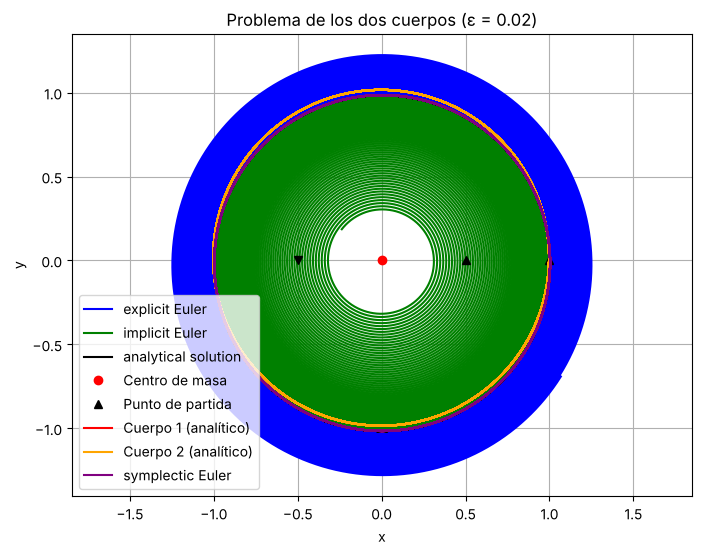

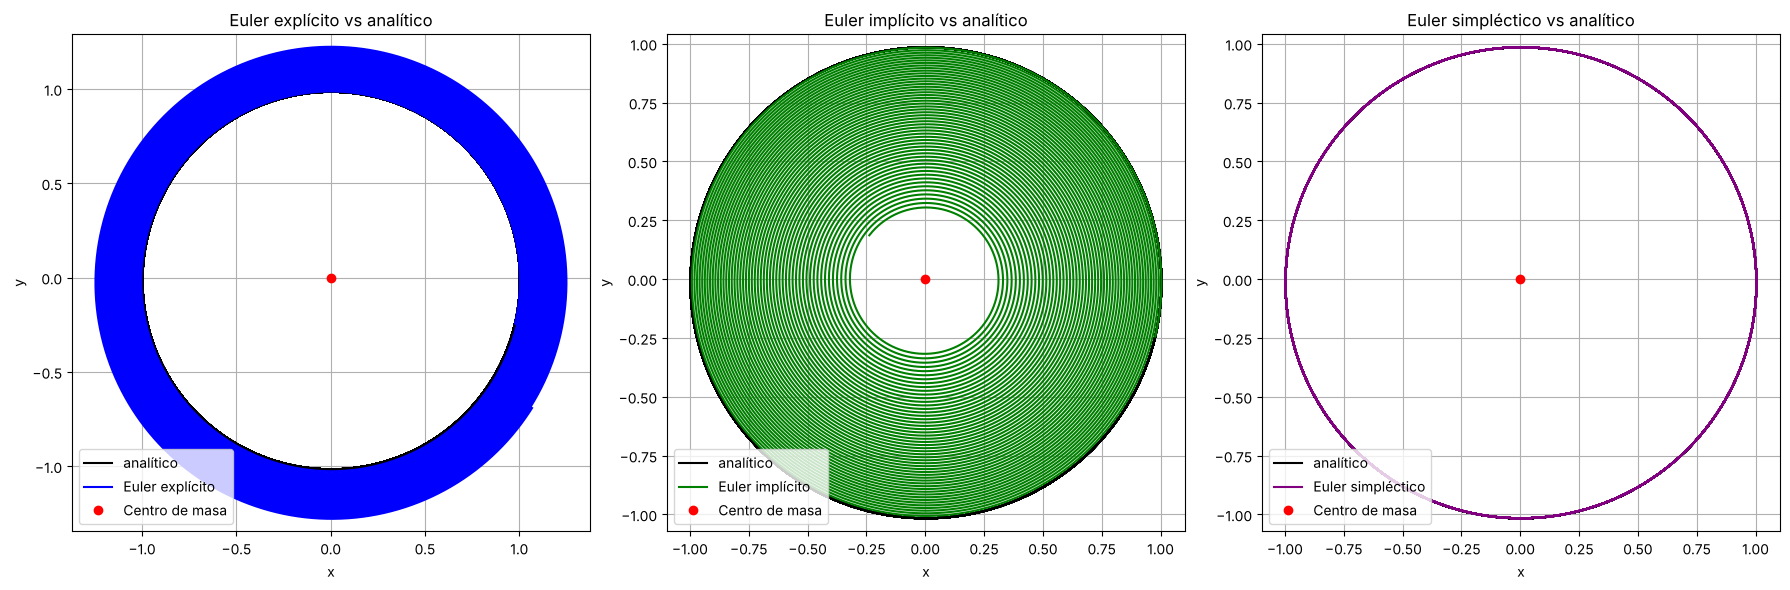

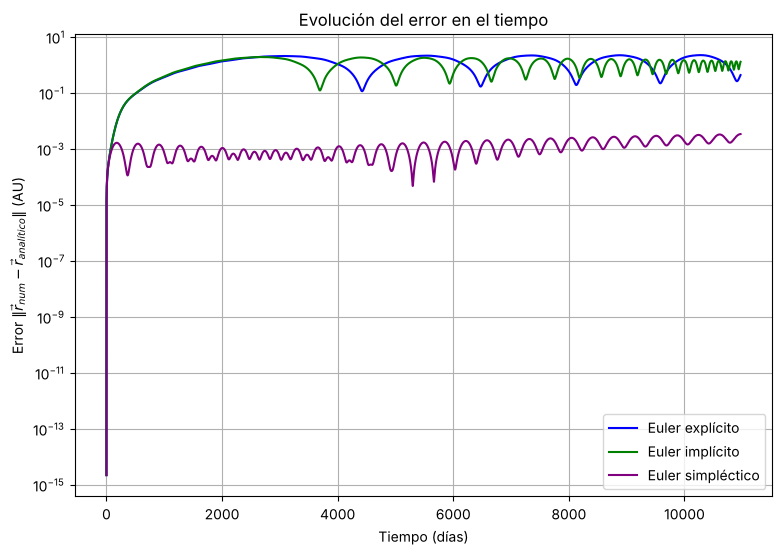

Órbita               Explícito (min/máx)             Implícito (min/máx)           Simpléctico (min/máx)
1             2.222e-15        5.275e-02      2.222e-15        5.363e-02      2.222e-15        1.653e-03
2             5.276e-02        2.018e-01      5.364e-02        2.107e-01      1.130e-04        1.538e-03
3             2.018e-01        4.421e-01      2.107e-01        4.732e-01      2.250e-04        1.423e-03
4             4.421e-01        7.609e-01      4.732e-01        8.319e-01      3.037e-04        1.309e-03
5             7.610e-01        1.134e+00      8.319e-01        1.253e+00      3.534e-04        1.194e-03
6             1.134e+00        1.520e+00      1.253e+00        1.656e+00      3.856e-04        1.079e-03
7             1.520e+00        1.857e+00      1.656e+00        1.901e+00      4.045e-04        9.647e-04
8             1.857e+00        2.061e+00      1.804e+00        1.912e+00      4.121e-04        9.044e-04
9             2.036e+00        2.088e+00      1.216e+00

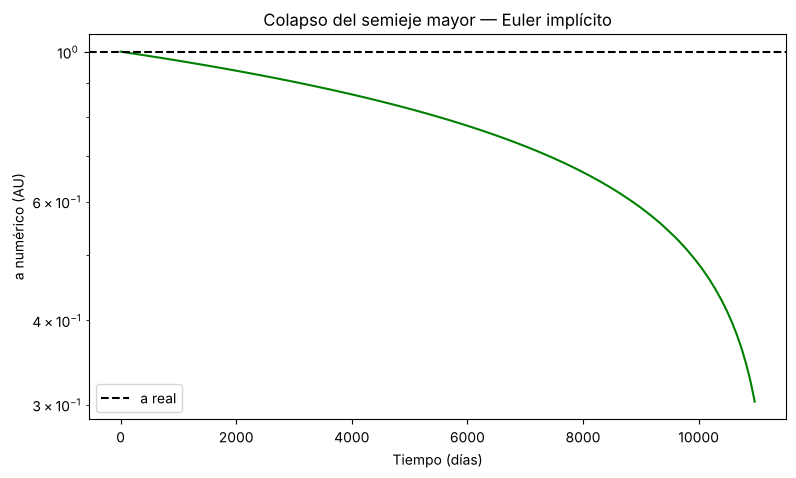

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton, root

#cantidad de orbitas

n_orbitas = 30

#pasos a considerar, notese que entre mayor el paso mejor se notan los cambios,
#en cambio, si usamos pasos muy cortos se extiende el tiempo de compilacion
delta_t = 0.05

# --- Parameters and initial conditions / Parámetros y condiciones iniciales---
G = 2.95912208286e-4   # gravitational constant / constante gravitacional
m1 = 1.0       # masa del sol relativa
m2 = 3.00348959632e-6 # mass de la tierra relativa
M = m1 + m2 # Total mass / Masa total
mu = (m1 * m2) / M

# Start at perihelion on the x-axis / Inicio en el perihelio en el eje x
r0 = np.array([9.773607012272747e-01,-2.440933024736090e-01]) # Initial position / Position initala
v_kreis = np.sqrt(G * M / np.linalg.norm(r0)) # velocity for a circle / velocidad para un circulo
# For a flatter ellipse, use e.g., 1.35 / Para una elipse más plana, usa p.ej. 1.35
v0 = np.array([3.894601620572785e-03, 1.663271328584905e-02])
p0 = v0 * mu

# --- Calculate orbital prameters / Calcular parámetros orbitales ---
r0_norm = np.linalg.norm(r0)
v0_norm = np.linalg.norm(v0)

E_spec = 0.5 * v0_norm**2 - (G * M) / r0_norm # specific energy / energia especifica
a = - (G * M) / (2.0 * E_spec)
h = r0[0]*v0[1] - r0[1]*v0[0] # momentum / momento
epsilon = np.sqrt(1.0 - (h**2) / (G * M * a))

T_orbit = 2.0 * np.pi * np.sqrt(a**3 / (G * M)) #orbital period / periodo orbital
print(T_orbit)
n = np.sqrt(G * M / a**3) # mean motion / movimiento medio

# --- Orientacion y fase de la elipse a partir de r0, v0 (SOLUCION ANALITICA ARREGLADA) ---
# vector de excentricidad: apunta al perihelio
e_vec = (v0_norm**2 / (G * M) - 1.0 / r0_norm) * r0 - (np.dot(r0, v0) / (G * M)) * v0
omega = np.arctan2(e_vec[1], e_vec[0])   # angulo del perihelio

# anomalia verdadera inicial (donde esta la Tierra en t=0)
nu0 = np.arccos(np.clip(np.dot(e_vec, r0) / (np.linalg.norm(e_vec) * r0_norm), -1.0, 1.0))
if np.dot(r0, v0) < 0:          # se acerca al Sol -> segunda mitad de la orbita
    nu0 = 2.0 * np.pi - nu0

# anomalia excentrica y media iniciales
E0 = 2.0 * np.arctan2(np.sqrt(1.0 - epsilon) * np.sin(nu0 / 2), np.sqrt(1.0 + epsilon) * np.cos(nu0 / 2))
M0 = E0 - epsilon * np.sin(E0)

# matriz de rotacion en omega
Rot = np.array([[np.cos(omega), -np.sin(omega)],
                [np.sin(omega),  np.cos(omega)]])


# --- Calculate analytical solution / calcualr solución analitica ---
# evaluate one full orbit t \in [0,T_orbit]
t_eval = np.linspace(0, n_orbitas*T_orbit, n_orbitas*200) #########################################################3
r_analytical = np.zeros((len(t_eval),2))

for i, t in enumerate(t_eval):
    M_anom = M0 + n * t # mean anomaly / anomalia media

    # define Kepler's equation / definir ecuacíon de Kepler: f(E) = E-e*sin(E)-M(t) = 0
    def kepler_eq(E):
        return E - epsilon *np.sin(E) - M_anom
    # Derivatvie of Kepler's equation for faster Newton's method/
    # Derivida para el método de Newton
    def kepler_prime(E):
        return 1.0 - epsilon * np.cos(E)

    # Newton's method (M_anom is a good initial guess) / Método de Newton (M_anom es una buena estimación inicial)
    E_sol = newton(kepler_eq, x0=M_anom, fprime=kepler_prime)

    # Calculate de position in the x,y-plane / Calcular posición en el plano x,y
    x = a * (np.cos(E_sol) - epsilon)
    y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)

    r_analytical[i] = Rot @ np.array([x, y])


# --- Calculate numerical solution using Euler explicit, implicit and symplectic
def grav_force(r):
    r_norm = np.linalg.norm(r)
    return -(G * M * mu) * r / (r_norm**3)

# Explicit Euler

n_steps = int(T_orbit/delta_t)*n_orbitas ###############################################################

r_explicit = np.zeros((n_steps + 1, 2))
p_explicit = np.zeros((n_steps + 1, 2))
r_explicit[0] = r0
p_explicit[0] = p0

for i in range(n_steps):
    r_old = r_explicit[i]
    p_old = p_explicit[i]

    r_explicit[i+1] = r_old + delta_t * (p_old / mu)
    p_explicit[i+1] = p_old + delta_t * grav_force(r_old)

# Implicit Euler

n_steps = n_steps
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    r_guess = r_old + delta_t * (p_old/ mu) #explicit step

    sol = root(residual, r_guess)
    r_next = sol.x

    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i+1] = r_next
    p_implicit[i+1] = p_next

#Euler simplectico


n_steps = int(T_orbit/delta_t)*n_orbitas   ##################################################################

r_symplectic = np.zeros((n_steps + 1, 2))
p_symplectic = np.zeros((n_steps + 1, 2))
r_symplectic[0] = r0
p_symplectic[0] = p0

for i in range(n_steps):
    r_old = r_symplectic[i]
    p_old = p_symplectic[i]

    r_symplectic[i+1] = r_old + delta_t * (p_old / mu)
    p_symplectic[i+1] = p_old + delta_t * grav_force(r_symplectic[i+1])

# --- Visualization of the relative vector between the two bodies---
plt.figure(figsize=(8, 6))
plt.plot(r_explicit[:, 0], r_explicit[:, 1], label="explicit Euler", color="blue")
plt.plot(r_implicit[:, 0], r_implicit[:, 1], label="implicit Euler", color="green")
plt.plot(r_analytical[:, 0], r_analytical[:, 1], label="analytical solution", color="black")

plt.plot(0, 0, 'ro', label="Centro de masa")
plt.plot(1, 0, 'k^', label = "Punto de partida")


#Visualizacion de los dos cuerpos:
# Conversión del vector relativo a coordenadas del centro de masa
#r1 = +(m2 / M) * r  und  r2 = -(m1 / M) * r
r1_analytical = (m2 / M) * r_analytical
r2_analytical = -(m1 / M) * r_analytical

# plot of the two bodies
plt.plot(r1_analytical[:, 0], r1_analytical[:, 1], label="Cuerpo 1 (analítico)", color="red")
plt.plot(r2_analytical[:, 0], r2_analytical[:, 1], label="Cuerpo 2 (analítico)", color="orange")
plt.plot(r_symplectic[:, 0], r_symplectic[:, 1], label="symplectic Euler", color="purple")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Problema de los dos cuerpos (ε = {epsilon:.2f})")
plt.axis("equal")
plt.legend(loc='lower left')
plt.grid(True)
plt.plot(0.5, 0, 'k^', label = "Punto de partida")
plt.plot(-0.5, 0, 'kv', label = "Punto de partida")

plt.show()

#Visualización: analítico vs cada método por separado
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

metodos = [
    (r_explicit, "Euler explícito", "blue"),
    (r_implicit, "Euler implícito", "green"),
    (r_symplectic, "Euler simpléctico", "purple"),
]

for ax, (r_num, nombre, color) in zip(axs, metodos):
    ax.plot(r_analytical[:, 0], r_analytical[:, 1], label="analítico", color="black")
    ax.plot(r_num[:, 0], r_num[:, 1], label=nombre, color=color)
    ax.plot(0, 0, 'ro', label="Centro de masa")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"{nombre} vs analítico")
    ax.axis("equal")
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.show()
###################################################################################################################################################################
# ojo: calcula punto a punto y en consecuencia el codigo compila mas lento, solucionamos vectorizando :)
###################################################################################################################################################################

#t_sync = np.arange(n_steps + 1) * delta_t   # mismos instantes que usa tu loop: t_i = i*delta_t
# r_analytical_sync = np.zeros((n_steps + 1, 2))

# for i, t in enumerate(t_sync):
#     M_anom = n * t
#     E_sol = newton(lambda E: E - epsilon*np.sin(E) - M_anom,
#                     x0=M_anom,
#                     fprime=lambda E: 1.0 - epsilon*np.cos(E))
#     x = a * (np.cos(E_sol) - epsilon)
#     y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)
#     r_analytical_sync[i] = [x, y]

###################################################################################################################################################################



#creamos arreglos a vectorizar


t_sync = np.arange(n_steps + 1) * delta_t
M_anom = M0 + n * t_sync

# Newton-Raphson vectorizado: itera sobre TODO el arreglo a la vez
E = M_anom.copy()                      # estimación inicial
for _ in range(6):
    E = E - (E - epsilon*np.sin(E) - M_anom) / (1.0 - epsilon*np.cos(E))

r_analytical_sync = np.column_stack([
    a * (np.cos(E) - epsilon),
    a * np.sqrt(1.0 - epsilon**2) * np.sin(E)
]) @ Rot.T


#Error por metodo

error_explicit  = np.linalg.norm(r_explicit  - r_analytical_sync, axis=1)
error_implicit  = np.linalg.norm(r_implicit  - r_analytical_sync, axis=1)
error_symplectic = np.linalg.norm(r_symplectic - r_analytical_sync, axis=1)


plt.figure(figsize=(9, 6))
plt.plot(t_sync, error_explicit, label="Euler explícito", color="blue")
plt.plot(t_sync, error_implicit, label="Euler implícito", color="green")
plt.plot(t_sync, error_symplectic, label="Euler simpléctico", color="purple")
plt.xlabel("Tiempo (días)")
plt.ylabel(r"Error $\|\vec r_{num} - \vec r_{analítico}\|$ (AU)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both")
plt.title("Evolución del error en el tiempo")
plt.show()


# --- Resumen numérico del error, órbita por órbita ---
pasos_por_orbita = int(T_orbit / delta_t)

print(f"{'Órbita':<8}{'Explícito (min/máx)':>32}{'Implícito (min/máx)':>32}{'Simpléctico (min/máx)':>32}")
for k in range(n_orbitas):
    ini = k * pasos_por_orbita
    fin = (k + 1) * pasos_por_orbita

    tramo_exp = error_explicit[ini:fin]
    tramo_imp = error_implicit[ini:fin]
    tramo_sym = error_symplectic[ini:fin]

    print(f"{k+1:<8}"
          f"{tramo_exp.min():>15.3e}{tramo_exp.max():>17.3e}"
          f"{tramo_imp.min():>15.3e}{tramo_imp.max():>17.3e}"
          f"{tramo_sym.min():>15.3e}{tramo_sym.max():>17.3e}")

#como, teoricamente, sabemos que el euler implicito va a ser mala aproximacion hacia el interior de la elipse,
#podemos observar el comportamiento para distintas cantidades de orbitas en un determinado paso

    v_implicit = p_implicit / mu
E_spec_num = 0.5*np.linalg.norm(v_implicit, axis=1)**2 - G*M/np.linalg.norm(r_implicit, axis=1)
a_num_implicit = -G*M/(2.0*E_spec_num)

plt.figure(figsize=(9,5))
plt.plot(t_sync, a_num_implicit, color="green")
plt.axhline(a, color="black", linestyle="--", label="a real")
plt.xlabel("Tiempo (días)")
plt.ylabel("a numérico (AU)")
plt.yscale("log")
plt.legend()
plt.title("Colapso del semieje mayor — Euler implícito")
plt.show()

SIMULACIÓN CON 40 ÓRBITAS

365.69735885301816


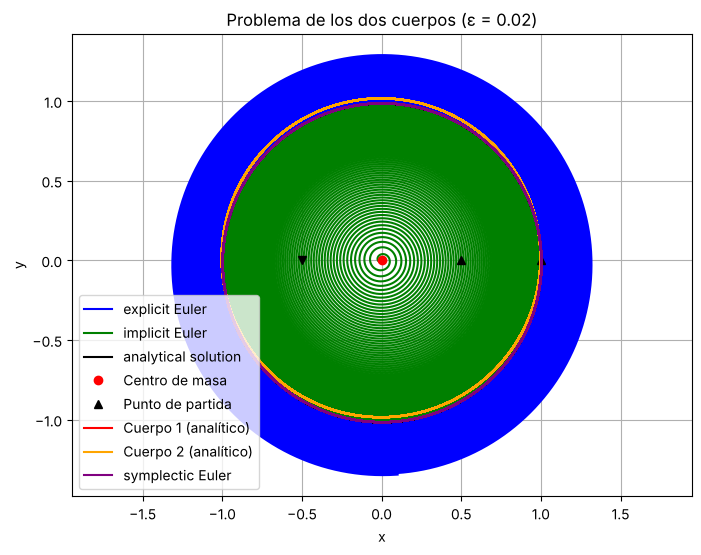

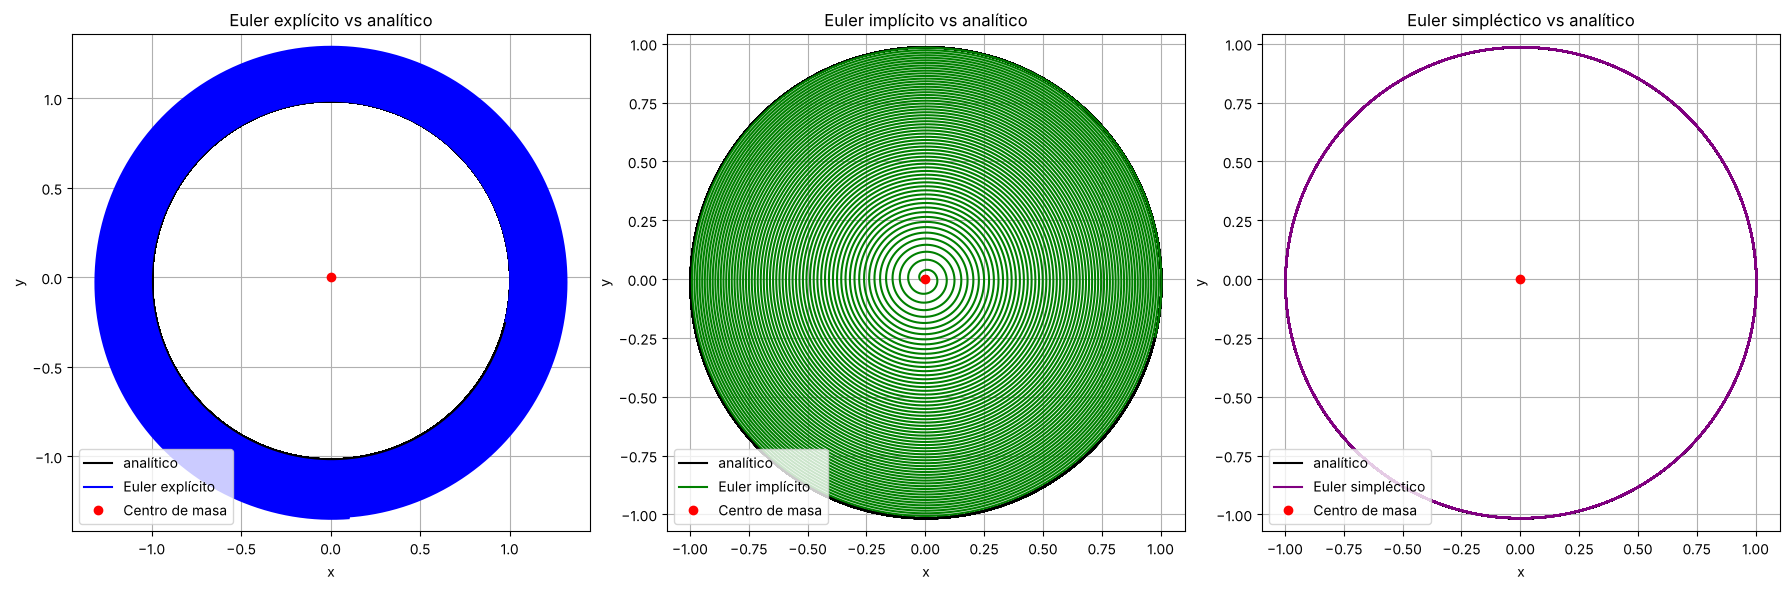

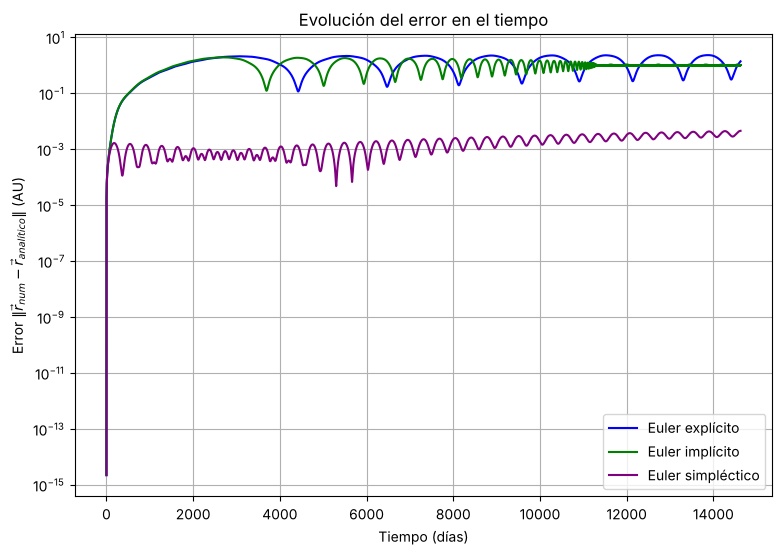

Órbita               Explícito (min/máx)             Implícito (min/máx)           Simpléctico (min/máx)
1             2.222e-15        5.275e-02      2.222e-15        5.363e-02      2.222e-15        1.653e-03
2             5.276e-02        2.018e-01      5.364e-02        2.107e-01      1.130e-04        1.538e-03
3             2.018e-01        4.421e-01      2.107e-01        4.732e-01      2.250e-04        1.423e-03
4             4.421e-01        7.609e-01      4.732e-01        8.319e-01      3.037e-04        1.309e-03
5             7.610e-01        1.134e+00      8.319e-01        1.253e+00      3.534e-04        1.194e-03
6             1.134e+00        1.520e+00      1.253e+00        1.656e+00      3.856e-04        1.079e-03
7             1.520e+00        1.857e+00      1.656e+00        1.901e+00      4.045e-04        9.647e-04
8             1.857e+00        2.061e+00      1.804e+00        1.912e+00      4.121e-04        9.044e-04
9             2.036e+00        2.088e+00      1.216e+00

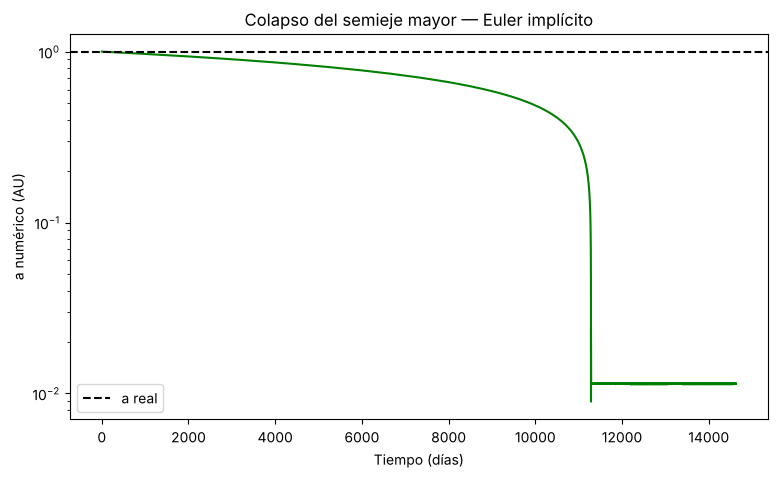

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton, root

#cantidad de orbitas

n_orbitas = 40

#pasos a considerar, notese que entre mayor el paso mejor se notan los cambios,
#en cambio, si usamos pasos muy cortos se extiende el tiempo de compilacion
delta_t = 0.05

# --- Parameters and initial conditions / Parámetros y condiciones iniciales---
G = 2.95912208286e-4   # gravitational constant / constante gravitacional
m1 = 1.0       # masa del sol relativa
m2 = 3.00348959632e-6 # mass de la tierra relativa
M = m1 + m2 # Total mass / Masa total
mu = (m1 * m2) / M

# Start at perihelion on the x-axis / Inicio en el perihelio en el eje x
r0 = np.array([9.773607012272747e-01,-2.440933024736090e-01]) # Initial position / Position initala
v_kreis = np.sqrt(G * M / np.linalg.norm(r0)) # velocity for a circle / velocidad para un circulo
# For a flatter ellipse, use e.g., 1.35 / Para una elipse más plana, usa p.ej. 1.35
v0 = np.array([3.894601620572785e-03, 1.663271328584905e-02])
p0 = v0 * mu

# --- Calculate orbital prameters / Calcular parámetros orbitales ---
r0_norm = np.linalg.norm(r0)
v0_norm = np.linalg.norm(v0)

E_spec = 0.5 * v0_norm**2 - (G * M) / r0_norm # specific energy / energia especifica
a = - (G * M) / (2.0 * E_spec)
h = r0[0]*v0[1] - r0[1]*v0[0] # momentum / momento
epsilon = np.sqrt(1.0 - (h**2) / (G * M * a))

T_orbit = 2.0 * np.pi * np.sqrt(a**3 / (G * M)) #orbital period / periodo orbital
print(T_orbit)
n = np.sqrt(G * M / a**3) # mean motion / movimiento medio

# --- Orientacion y fase de la elipse a partir de r0, v0 (SOLUCION ANALITICA ARREGLADA) ---
# vector de excentricidad: apunta al perihelio
e_vec = (v0_norm**2 / (G * M) - 1.0 / r0_norm) * r0 - (np.dot(r0, v0) / (G * M)) * v0
omega = np.arctan2(e_vec[1], e_vec[0])   # angulo del perihelio

# anomalia verdadera inicial (donde esta la Tierra en t=0)
nu0 = np.arccos(np.clip(np.dot(e_vec, r0) / (np.linalg.norm(e_vec) * r0_norm), -1.0, 1.0))
if np.dot(r0, v0) < 0:          # se acerca al Sol -> segunda mitad de la orbita
    nu0 = 2.0 * np.pi - nu0

# anomalia excentrica y media iniciales
E0 = 2.0 * np.arctan2(np.sqrt(1.0 - epsilon) * np.sin(nu0 / 2), np.sqrt(1.0 + epsilon) * np.cos(nu0 / 2))
M0 = E0 - epsilon * np.sin(E0)

# matriz de rotacion en omega
Rot = np.array([[np.cos(omega), -np.sin(omega)],
                [np.sin(omega),  np.cos(omega)]])


# --- Calculate analytical solution / calcualr solución analitica ---
# evaluate one full orbit t \in [0,T_orbit]
t_eval = np.linspace(0, n_orbitas*T_orbit, n_orbitas*200) #########################################################3
r_analytical = np.zeros((len(t_eval),2))

for i, t in enumerate(t_eval):
    M_anom = M0 + n * t # mean anomaly / anomalia media

    # define Kepler's equation / definir ecuacíon de Kepler: f(E) = E-e*sin(E)-M(t) = 0
    def kepler_eq(E):
        return E - epsilon *np.sin(E) - M_anom
    # Derivatvie of Kepler's equation for faster Newton's method/
    # Derivida para el método de Newton
    def kepler_prime(E):
        return 1.0 - epsilon * np.cos(E)

    # Newton's method (M_anom is a good initial guess) / Método de Newton (M_anom es una buena estimación inicial)
    E_sol = newton(kepler_eq, x0=M_anom, fprime=kepler_prime)

    # Calculate de position in the x,y-plane / Calcular posición en el plano x,y
    x = a * (np.cos(E_sol) - epsilon)
    y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)

    r_analytical[i] = Rot @ np.array([x, y])


# --- Calculate numerical solution using Euler explicit, implicit and symplectic
def grav_force(r):
    r_norm = np.linalg.norm(r)
    return -(G * M * mu) * r / (r_norm**3)

# Explicit Euler

n_steps = int(T_orbit/delta_t)*n_orbitas ###############################################################

r_explicit = np.zeros((n_steps + 1, 2))
p_explicit = np.zeros((n_steps + 1, 2))
r_explicit[0] = r0
p_explicit[0] = p0

for i in range(n_steps):
    r_old = r_explicit[i]
    p_old = p_explicit[i]

    r_explicit[i+1] = r_old + delta_t * (p_old / mu)
    p_explicit[i+1] = p_old + delta_t * grav_force(r_old)

# Implicit Euler

n_steps = n_steps
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    r_guess = r_old + delta_t * (p_old/ mu) #explicit step

    sol = root(residual, r_guess)
    r_next = sol.x

    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i+1] = r_next
    p_implicit[i+1] = p_next

#Euler simplectico


n_steps = int(T_orbit/delta_t)*n_orbitas   ##################################################################

r_symplectic = np.zeros((n_steps + 1, 2))
p_symplectic = np.zeros((n_steps + 1, 2))
r_symplectic[0] = r0
p_symplectic[0] = p0

for i in range(n_steps):
    r_old = r_symplectic[i]
    p_old = p_symplectic[i]

    r_symplectic[i+1] = r_old + delta_t * (p_old / mu)
    p_symplectic[i+1] = p_old + delta_t * grav_force(r_symplectic[i+1])

# --- Visualization of the relative vector between the two bodies---
plt.figure(figsize=(8, 6))
plt.plot(r_explicit[:, 0], r_explicit[:, 1], label="explicit Euler", color="blue")
plt.plot(r_implicit[:, 0], r_implicit[:, 1], label="implicit Euler", color="green")
plt.plot(r_analytical[:, 0], r_analytical[:, 1], label="analytical solution", color="black")

plt.plot(0, 0, 'ro', label="Centro de masa")
plt.plot(1, 0, 'k^', label = "Punto de partida")


#Visualizacion de los dos cuerpos:
# Conversión del vector relativo a coordenadas del centro de masa
#r1 = +(m2 / M) * r  und  r2 = -(m1 / M) * r
r1_analytical = (m2 / M) * r_analytical
r2_analytical = -(m1 / M) * r_analytical

# plot of the two bodies
plt.plot(r1_analytical[:, 0], r1_analytical[:, 1], label="Cuerpo 1 (analítico)", color="red")
plt.plot(r2_analytical[:, 0], r2_analytical[:, 1], label="Cuerpo 2 (analítico)", color="orange")
plt.plot(r_symplectic[:, 0], r_symplectic[:, 1], label="symplectic Euler", color="purple")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Problema de los dos cuerpos (ε = {epsilon:.2f})")
plt.axis("equal")
plt.legend(loc='lower left')
plt.grid(True)
plt.plot(0.5, 0, 'k^', label = "Punto de partida")
plt.plot(-0.5, 0, 'kv', label = "Punto de partida")

plt.show()

#Visualización: analítico vs cada método por separado
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

metodos = [
    (r_explicit, "Euler explícito", "blue"),
    (r_implicit, "Euler implícito", "green"),
    (r_symplectic, "Euler simpléctico", "purple"),
]

for ax, (r_num, nombre, color) in zip(axs, metodos):
    ax.plot(r_analytical[:, 0], r_analytical[:, 1], label="analítico", color="black")
    ax.plot(r_num[:, 0], r_num[:, 1], label=nombre, color=color)
    ax.plot(0, 0, 'ro', label="Centro de masa")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"{nombre} vs analítico")
    ax.axis("equal")
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.show()
###################################################################################################################################################################
# ojo: calcula punto a punto y en consecuencia el codigo compila mas lento, solucionamos vectorizando :)
###################################################################################################################################################################

#t_sync = np.arange(n_steps + 1) * delta_t   # mismos instantes que usa tu loop: t_i = i*delta_t
# r_analytical_sync = np.zeros((n_steps + 1, 2))

# for i, t in enumerate(t_sync):
#     M_anom = n * t
#     E_sol = newton(lambda E: E - epsilon*np.sin(E) - M_anom,
#                     x0=M_anom,
#                     fprime=lambda E: 1.0 - epsilon*np.cos(E))
#     x = a * (np.cos(E_sol) - epsilon)
#     y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)
#     r_analytical_sync[i] = [x, y]

###################################################################################################################################################################



#creamos arreglos a vectorizar


t_sync = np.arange(n_steps + 1) * delta_t
M_anom = M0 + n * t_sync

# Newton-Raphson vectorizado: itera sobre TODO el arreglo a la vez
E = M_anom.copy()                      # estimación inicial
for _ in range(6):
    E = E - (E - epsilon*np.sin(E) - M_anom) / (1.0 - epsilon*np.cos(E))

r_analytical_sync = np.column_stack([
    a * (np.cos(E) - epsilon),
    a * np.sqrt(1.0 - epsilon**2) * np.sin(E)
]) @ Rot.T


#Error por metodo

error_explicit  = np.linalg.norm(r_explicit  - r_analytical_sync, axis=1)
error_implicit  = np.linalg.norm(r_implicit  - r_analytical_sync, axis=1)
error_symplectic = np.linalg.norm(r_symplectic - r_analytical_sync, axis=1)


plt.figure(figsize=(9, 6))
plt.plot(t_sync, error_explicit, label="Euler explícito", color="blue")
plt.plot(t_sync, error_implicit, label="Euler implícito", color="green")
plt.plot(t_sync, error_symplectic, label="Euler simpléctico", color="purple")
plt.xlabel("Tiempo (días)")
plt.ylabel(r"Error $\|\vec r_{num} - \vec r_{analítico}\|$ (AU)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both")
plt.title("Evolución del error en el tiempo")
plt.show()


# --- Resumen numérico del error, órbita por órbita ---
pasos_por_orbita = int(T_orbit / delta_t)

print(f"{'Órbita':<8}{'Explícito (min/máx)':>32}{'Implícito (min/máx)':>32}{'Simpléctico (min/máx)':>32}")
for k in range(n_orbitas):
    ini = k * pasos_por_orbita
    fin = (k + 1) * pasos_por_orbita

    tramo_exp = error_explicit[ini:fin]
    tramo_imp = error_implicit[ini:fin]
    tramo_sym = error_symplectic[ini:fin]

    print(f"{k+1:<8}"
          f"{tramo_exp.min():>15.3e}{tramo_exp.max():>17.3e}"
          f"{tramo_imp.min():>15.3e}{tramo_imp.max():>17.3e}"
          f"{tramo_sym.min():>15.3e}{tramo_sym.max():>17.3e}")

#como, teoricamente, sabemos que el euler implicito va a ser mala aproximacion hacia el interior de la elipse,
#podemos observar el comportamiento para distintas cantidades de orbitas en un determinado paso

    v_implicit = p_implicit / mu
E_spec_num = 0.5*np.linalg.norm(v_implicit, axis=1)**2 - G*M/np.linalg.norm(r_implicit, axis=1)
a_num_implicit = -G*M/(2.0*E_spec_num)

plt.figure(figsize=(9,5))
plt.plot(t_sync, a_num_implicit, color="green")
plt.axhline(a, color="black", linestyle="--", label="a real")
plt.xlabel("Tiempo (días)")
plt.ylabel("a numérico (AU)")
plt.yscale("log")
plt.legend()
plt.title("Colapso del semieje mayor — Euler implícito")
plt.show()

SIMULACIÓN CON 50 ÓRBITAS

365.69735885301816


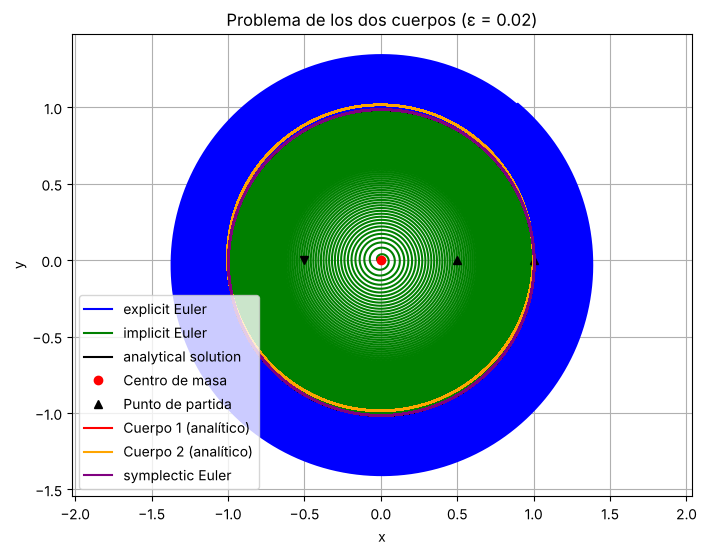

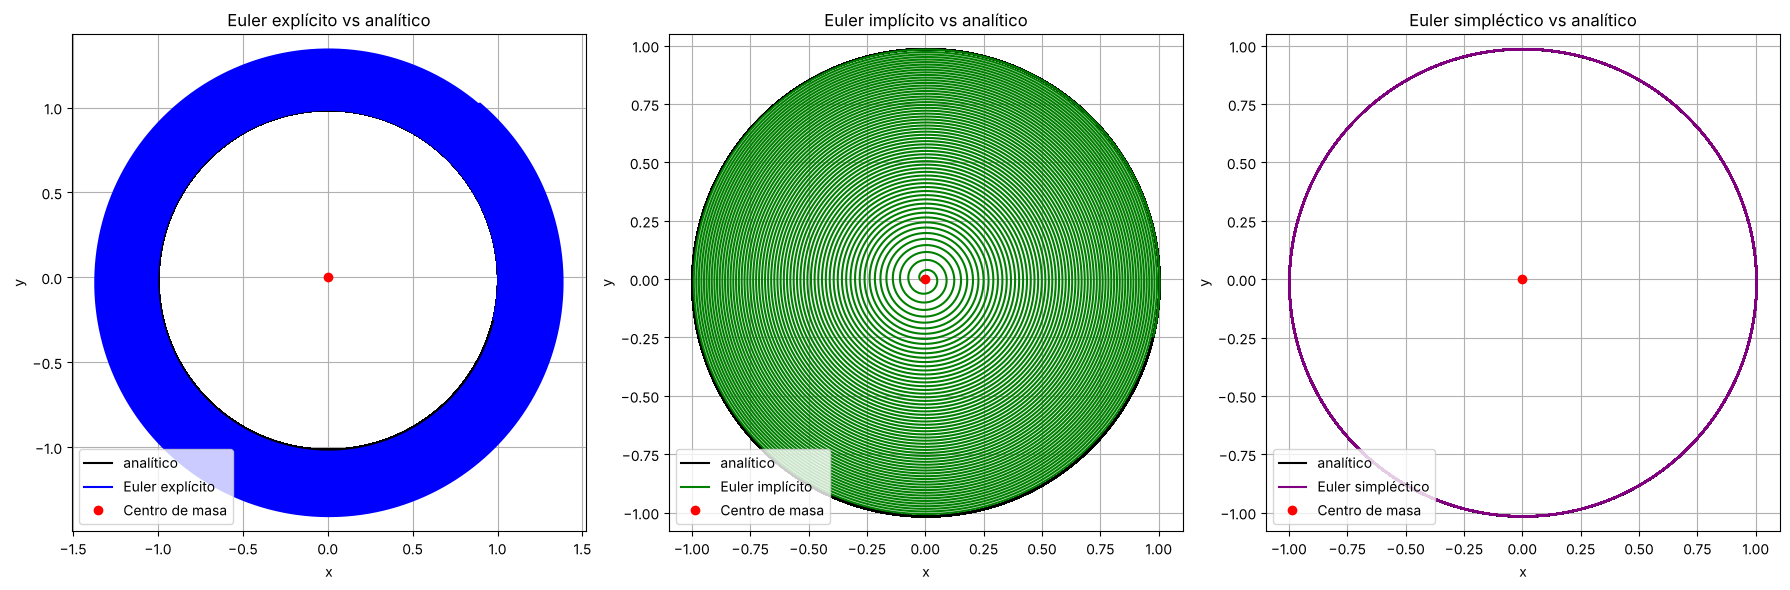

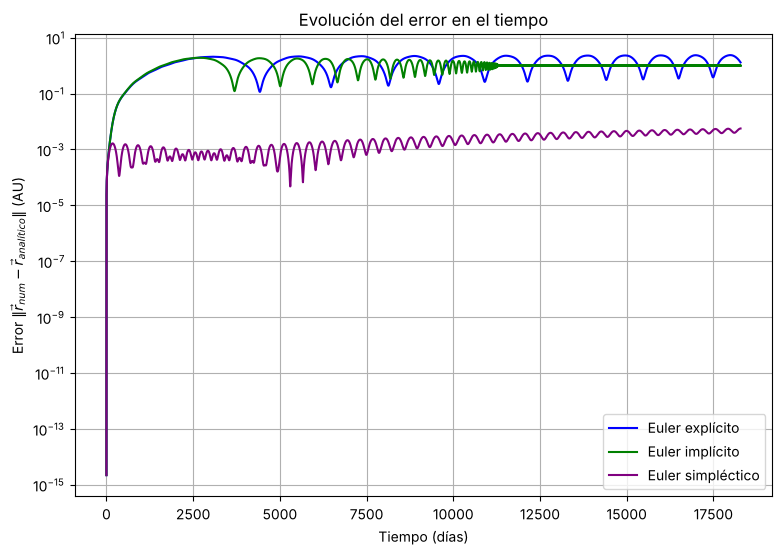

Órbita               Explícito (min/máx)             Implícito (min/máx)           Simpléctico (min/máx)
1             2.222e-15        5.275e-02      2.222e-15        5.363e-02      2.222e-15        1.653e-03
2             5.276e-02        2.018e-01      5.364e-02        2.107e-01      1.130e-04        1.538e-03
3             2.018e-01        4.421e-01      2.107e-01        4.732e-01      2.250e-04        1.423e-03
4             4.421e-01        7.609e-01      4.732e-01        8.319e-01      3.037e-04        1.309e-03
5             7.610e-01        1.134e+00      8.319e-01        1.253e+00      3.534e-04        1.194e-03
6             1.134e+00        1.520e+00      1.253e+00        1.656e+00      3.856e-04        1.079e-03
7             1.520e+00        1.857e+00      1.656e+00        1.901e+00      4.045e-04        9.647e-04
8             1.857e+00        2.061e+00      1.804e+00        1.912e+00      4.121e-04        9.044e-04
9             2.036e+00        2.088e+00      1.216e+00

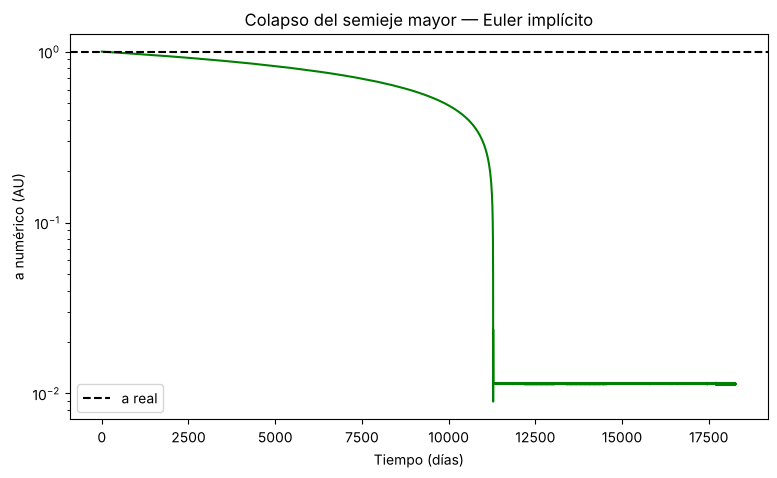

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton, root

#cantidad de orbitas

n_orbitas = 50

#pasos a considerar, notese que entre mayor el paso mejor se notan los cambios,
#en cambio, si usamos pasos muy cortos se extiende el tiempo de compilacion
delta_t = 0.05

# --- Parameters and initial conditions / Parámetros y condiciones iniciales---
G = 2.95912208286e-4   # gravitational constant / constante gravitacional
m1 = 1.0       # masa del sol relativa
m2 = 3.00348959632e-6 # mass de la tierra relativa
M = m1 + m2 # Total mass / Masa total
mu = (m1 * m2) / M

# Start at perihelion on the x-axis / Inicio en el perihelio en el eje x
r0 = np.array([9.773607012272747e-01,-2.440933024736090e-01]) # Initial position / Position initala
v_kreis = np.sqrt(G * M / np.linalg.norm(r0)) # velocity for a circle / velocidad para un circulo
# For a flatter ellipse, use e.g., 1.35 / Para una elipse más plana, usa p.ej. 1.35
v0 = np.array([3.894601620572785e-03, 1.663271328584905e-02])
p0 = v0 * mu

# --- Calculate orbital prameters / Calcular parámetros orbitales ---
r0_norm = np.linalg.norm(r0)
v0_norm = np.linalg.norm(v0)

E_spec = 0.5 * v0_norm**2 - (G * M) / r0_norm # specific energy / energia especifica
a = - (G * M) / (2.0 * E_spec)
h = r0[0]*v0[1] - r0[1]*v0[0] # momentum / momento
epsilon = np.sqrt(1.0 - (h**2) / (G * M * a))

T_orbit = 2.0 * np.pi * np.sqrt(a**3 / (G * M)) #orbital period / periodo orbital
print(T_orbit)
n = np.sqrt(G * M / a**3) # mean motion / movimiento medio

# --- Orientacion y fase de la elipse a partir de r0, v0 (SOLUCION ANALITICA ARREGLADA) ---
# vector de excentricidad: apunta al perihelio
e_vec = (v0_norm**2 / (G * M) - 1.0 / r0_norm) * r0 - (np.dot(r0, v0) / (G * M)) * v0
omega = np.arctan2(e_vec[1], e_vec[0])   # angulo del perihelio

# anomalia verdadera inicial (donde esta la Tierra en t=0)
nu0 = np.arccos(np.clip(np.dot(e_vec, r0) / (np.linalg.norm(e_vec) * r0_norm), -1.0, 1.0))
if np.dot(r0, v0) < 0:          # se acerca al Sol -> segunda mitad de la orbita
    nu0 = 2.0 * np.pi - nu0

# anomalia excentrica y media iniciales
E0 = 2.0 * np.arctan2(np.sqrt(1.0 - epsilon) * np.sin(nu0 / 2), np.sqrt(1.0 + epsilon) * np.cos(nu0 / 2))
M0 = E0 - epsilon * np.sin(E0)

# matriz de rotacion en omega
Rot = np.array([[np.cos(omega), -np.sin(omega)],
                [np.sin(omega),  np.cos(omega)]])


# --- Calculate analytical solution / calcualr solución analitica ---
# evaluate one full orbit t \in [0,T_orbit]
t_eval = np.linspace(0, n_orbitas*T_orbit, n_orbitas*200) #########################################################3
r_analytical = np.zeros((len(t_eval),2))

for i, t in enumerate(t_eval):
    M_anom = M0 + n * t # mean anomaly / anomalia media

    # define Kepler's equation / definir ecuacíon de Kepler: f(E) = E-e*sin(E)-M(t) = 0
    def kepler_eq(E):
        return E - epsilon *np.sin(E) - M_anom
    # Derivatvie of Kepler's equation for faster Newton's method/
    # Derivida para el método de Newton
    def kepler_prime(E):
        return 1.0 - epsilon * np.cos(E)

    # Newton's method (M_anom is a good initial guess) / Método de Newton (M_anom es una buena estimación inicial)
    E_sol = newton(kepler_eq, x0=M_anom, fprime=kepler_prime)

    # Calculate de position in the x,y-plane / Calcular posición en el plano x,y
    x = a * (np.cos(E_sol) - epsilon)
    y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)

    r_analytical[i] = Rot @ np.array([x, y])


# --- Calculate numerical solution using Euler explicit, implicit and symplectic
def grav_force(r):
    r_norm = np.linalg.norm(r)
    return -(G * M * mu) * r / (r_norm**3)

# Explicit Euler

n_steps = int(T_orbit/delta_t)*n_orbitas ###############################################################

r_explicit = np.zeros((n_steps + 1, 2))
p_explicit = np.zeros((n_steps + 1, 2))
r_explicit[0] = r0
p_explicit[0] = p0

for i in range(n_steps):
    r_old = r_explicit[i]
    p_old = p_explicit[i]

    r_explicit[i+1] = r_old + delta_t * (p_old / mu)
    p_explicit[i+1] = p_old + delta_t * grav_force(r_old)

# Implicit Euler

n_steps = n_steps
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    r_guess = r_old + delta_t * (p_old/ mu) #explicit step

    sol = root(residual, r_guess)
    r_next = sol.x

    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i+1] = r_next
    p_implicit[i+1] = p_next

#Euler simplectico


n_steps = int(T_orbit/delta_t)*n_orbitas   ##################################################################

r_symplectic = np.zeros((n_steps + 1, 2))
p_symplectic = np.zeros((n_steps + 1, 2))
r_symplectic[0] = r0
p_symplectic[0] = p0

for i in range(n_steps):
    r_old = r_symplectic[i]
    p_old = p_symplectic[i]

    r_symplectic[i+1] = r_old + delta_t * (p_old / mu)
    p_symplectic[i+1] = p_old + delta_t * grav_force(r_symplectic[i+1])

# --- Visualization of the relative vector between the two bodies---
plt.figure(figsize=(8, 6))
plt.plot(r_explicit[:, 0], r_explicit[:, 1], label="explicit Euler", color="blue")
plt.plot(r_implicit[:, 0], r_implicit[:, 1], label="implicit Euler", color="green")
plt.plot(r_analytical[:, 0], r_analytical[:, 1], label="analytical solution", color="black")

plt.plot(0, 0, 'ro', label="Centro de masa")
plt.plot(1, 0, 'k^', label = "Punto de partida")


#Visualizacion de los dos cuerpos:
# Conversión del vector relativo a coordenadas del centro de masa
#r1 = +(m2 / M) * r  und  r2 = -(m1 / M) * r
r1_analytical = (m2 / M) * r_analytical
r2_analytical = -(m1 / M) * r_analytical

# plot of the two bodies
plt.plot(r1_analytical[:, 0], r1_analytical[:, 1], label="Cuerpo 1 (analítico)", color="red")
plt.plot(r2_analytical[:, 0], r2_analytical[:, 1], label="Cuerpo 2 (analítico)", color="orange")
plt.plot(r_symplectic[:, 0], r_symplectic[:, 1], label="symplectic Euler", color="purple")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Problema de los dos cuerpos (ε = {epsilon:.2f})")
plt.axis("equal")
plt.legend(loc='lower left')
plt.grid(True)
plt.plot(0.5, 0, 'k^', label = "Punto de partida")
plt.plot(-0.5, 0, 'kv', label = "Punto de partida")

plt.show()

#Visualización: analítico vs cada método por separado
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

metodos = [
    (r_explicit, "Euler explícito", "blue"),
    (r_implicit, "Euler implícito", "green"),
    (r_symplectic, "Euler simpléctico", "purple"),
]

for ax, (r_num, nombre, color) in zip(axs, metodos):
    ax.plot(r_analytical[:, 0], r_analytical[:, 1], label="analítico", color="black")
    ax.plot(r_num[:, 0], r_num[:, 1], label=nombre, color=color)
    ax.plot(0, 0, 'ro', label="Centro de masa")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"{nombre} vs analítico")
    ax.axis("equal")
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.show()
###################################################################################################################################################################
# ojo: calcula punto a punto y en consecuencia el codigo compila mas lento, solucionamos vectorizando :)
###################################################################################################################################################################

#t_sync = np.arange(n_steps + 1) * delta_t   # mismos instantes que usa tu loop: t_i = i*delta_t
# r_analytical_sync = np.zeros((n_steps + 1, 2))

# for i, t in enumerate(t_sync):
#     M_anom = n * t
#     E_sol = newton(lambda E: E - epsilon*np.sin(E) - M_anom,
#                     x0=M_anom,
#                     fprime=lambda E: 1.0 - epsilon*np.cos(E))
#     x = a * (np.cos(E_sol) - epsilon)
#     y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)
#     r_analytical_sync[i] = [x, y]

###################################################################################################################################################################



#creamos arreglos a vectorizar


t_sync = np.arange(n_steps + 1) * delta_t
M_anom = M0 + n * t_sync

# Newton-Raphson vectorizado: itera sobre TODO el arreglo a la vez
E = M_anom.copy()                      # estimación inicial
for _ in range(6):
    E = E - (E - epsilon*np.sin(E) - M_anom) / (1.0 - epsilon*np.cos(E))

r_analytical_sync = np.column_stack([
    a * (np.cos(E) - epsilon),
    a * np.sqrt(1.0 - epsilon**2) * np.sin(E)
]) @ Rot.T


#Error por metodo

error_explicit  = np.linalg.norm(r_explicit  - r_analytical_sync, axis=1)
error_implicit  = np.linalg.norm(r_implicit  - r_analytical_sync, axis=1)
error_symplectic = np.linalg.norm(r_symplectic - r_analytical_sync, axis=1)


plt.figure(figsize=(9, 6))
plt.plot(t_sync, error_explicit, label="Euler explícito", color="blue")
plt.plot(t_sync, error_implicit, label="Euler implícito", color="green")
plt.plot(t_sync, error_symplectic, label="Euler simpléctico", color="purple")
plt.xlabel("Tiempo (días)")
plt.ylabel(r"Error $\|\vec r_{num} - \vec r_{analítico}\|$ (AU)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both")
plt.title("Evolución del error en el tiempo")
plt.show()


# --- Resumen numérico del error, órbita por órbita ---
pasos_por_orbita = int(T_orbit / delta_t)

print(f"{'Órbita':<8}{'Explícito (min/máx)':>32}{'Implícito (min/máx)':>32}{'Simpléctico (min/máx)':>32}")
for k in range(n_orbitas):
    ini = k * pasos_por_orbita
    fin = (k + 1) * pasos_por_orbita

    tramo_exp = error_explicit[ini:fin]
    tramo_imp = error_implicit[ini:fin]
    tramo_sym = error_symplectic[ini:fin]

    print(f"{k+1:<8}"
          f"{tramo_exp.min():>15.3e}{tramo_exp.max():>17.3e}"
          f"{tramo_imp.min():>15.3e}{tramo_imp.max():>17.3e}"
          f"{tramo_sym.min():>15.3e}{tramo_sym.max():>17.3e}")

#como, teoricamente, sabemos que el euler implicito va a ser mala aproximacion hacia el interior de la elipse,
#podemos observar el comportamiento para distintas cantidades de orbitas en un determinado paso

    v_implicit = p_implicit / mu
E_spec_num = 0.5*np.linalg.norm(v_implicit, axis=1)**2 - G*M/np.linalg.norm(r_implicit, axis=1)
a_num_implicit = -G*M/(2.0*E_spec_num)

plt.figure(figsize=(9,5))
plt.plot(t_sync, a_num_implicit, color="green")
plt.axhline(a, color="black", linestyle="--", label="a real")
plt.xlabel("Tiempo (días)")
plt.ylabel("a numérico (AU)")
plt.yscale("log")
plt.legend()
plt.title("Colapso del semieje mayor — Euler implícito")
plt.show()

SIMULACIÓN CON 20 ÓRBITAS + STÖRMER-VERLET / SIMULATION WITH 20 ORBITS + STÖRMER-VERLET

365.69735885301816


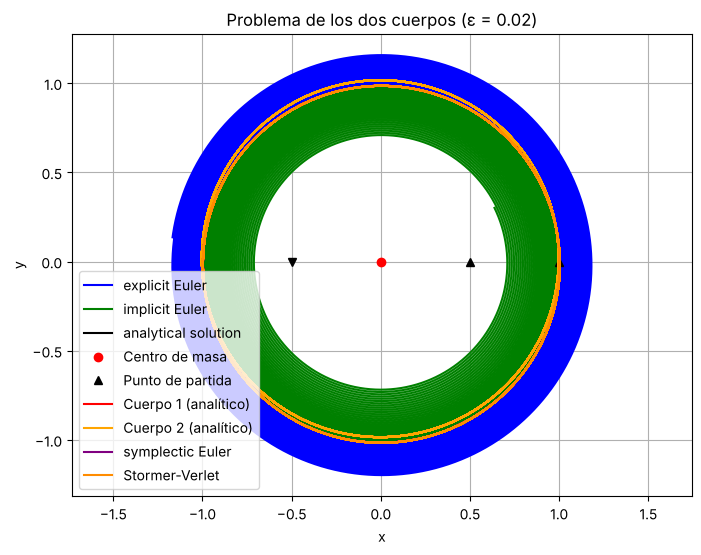

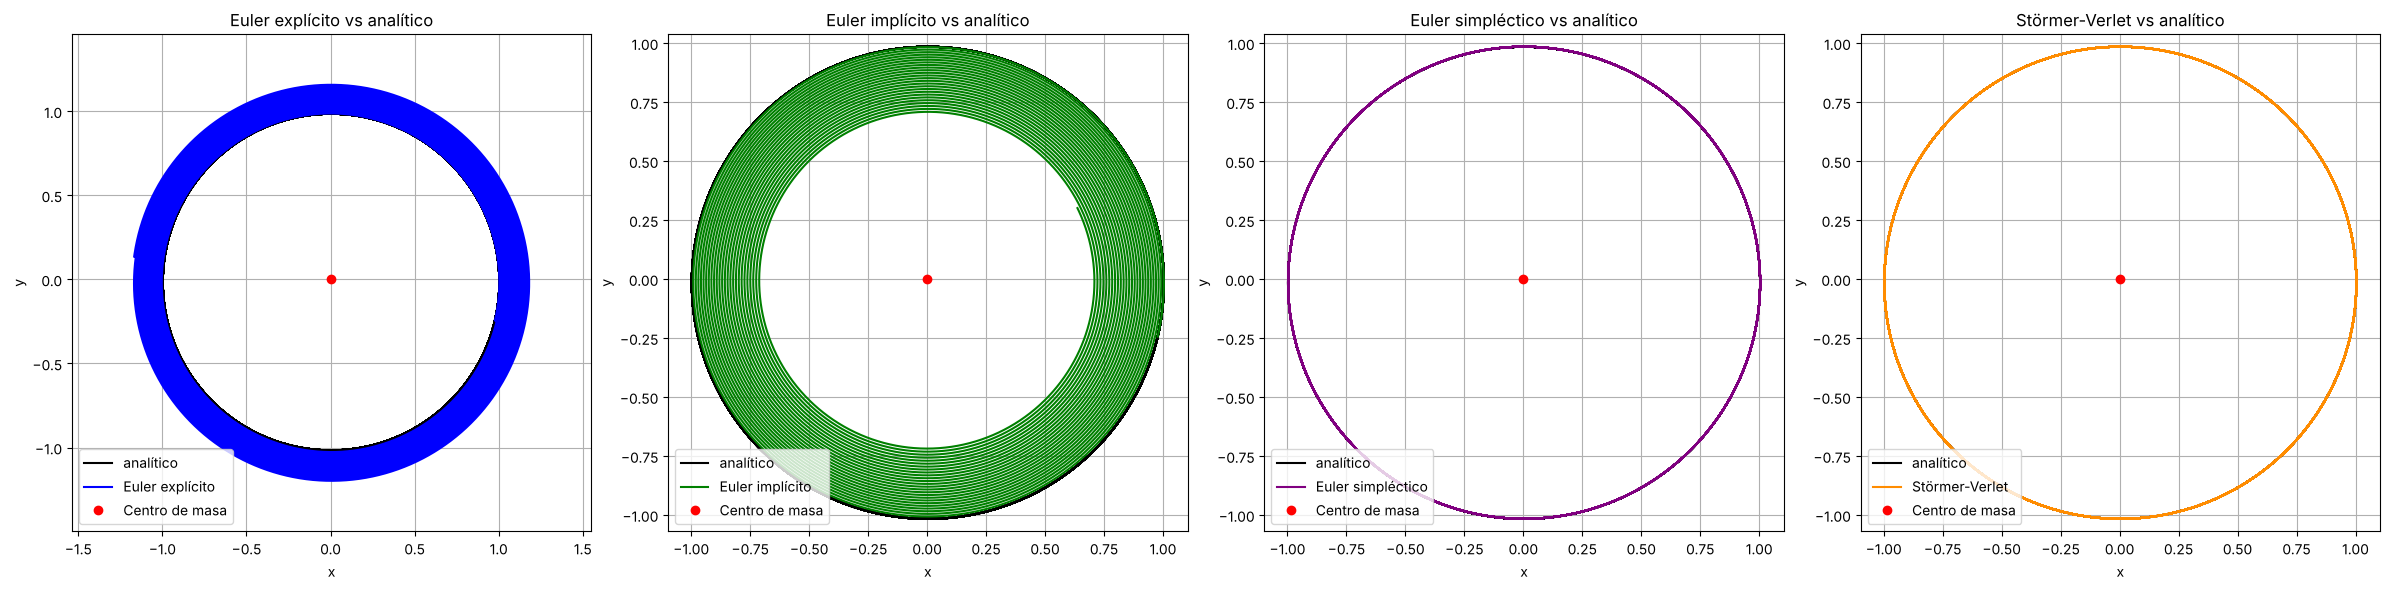

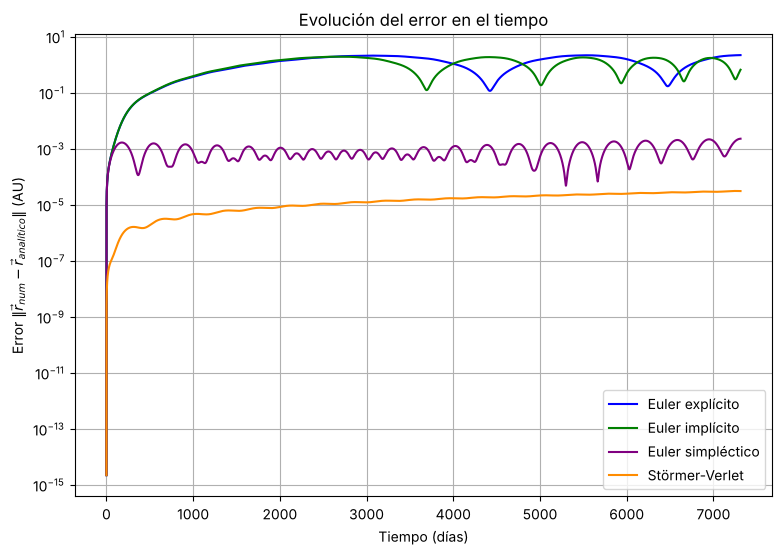

Órbita               Explícito (min/máx)             Implícito (min/máx)           Simpléctico (min/máx)                Verlet (min/máx)
1             2.222e-15        5.275e-02      2.222e-15        5.363e-02      2.222e-15        1.653e-03      2.222e-15        1.607e-06
2             5.276e-02        2.018e-01      5.364e-02        2.107e-01      1.130e-04        1.538e-03      1.455e-06        3.144e-06
3             2.018e-01        4.421e-01      2.107e-01        4.732e-01      2.250e-04        1.423e-03      2.974e-06        4.681e-06
4             4.421e-01        7.609e-01      4.732e-01        8.319e-01      3.037e-04        1.309e-03      4.492e-06        6.218e-06
5             7.610e-01        1.134e+00      8.319e-01        1.253e+00      3.534e-04        1.194e-03      6.010e-06        7.755e-06
6             1.134e+00        1.520e+00      1.253e+00        1.656e+00      3.856e-04        1.079e-03      7.527e-06        9.292e-06
7             1.520e+00        1.857e+00 

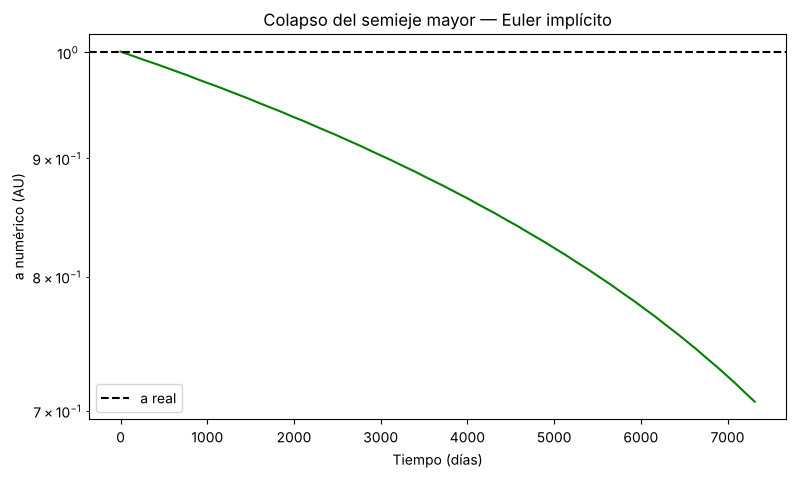

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton, root

#cantidad de orbitas

n_orbitas = 20

#pasos a considerar, notese que entre mayor el paso mejor se notan los cambios,
#en cambio, si usamos pasos muy cortos se extiende el tiempo de compilacion
delta_t = 0.05

# --- Parameters and initial conditions / Parámetros y condiciones iniciales---
G = 2.95912208286e-4   # gravitational constant / constante gravitacional
m1 = 1.0       # masa del sol relativa
m2 = 3.00348959632e-6 # mass de la tierra relativa
M = m1 + m2 # Total mass / Masa total
mu = (m1 * m2) / M

# Start at perihelion on the x-axis / Inicio en el perihelio en el eje x
r0 = np.array([9.773607012272747e-01,-2.440933024736090e-01]) # Initial position / Position initala
v_kreis = np.sqrt(G * M / np.linalg.norm(r0)) # velocity for a circle / velocidad para un circulo
# For a flatter ellipse, use e.g., 1.35 / Para una elipse más plana, usa p.ej. 1.35
v0 = np.array([3.894601620572785e-03, 1.663271328584905e-02])
p0 = v0 * mu

# --- Calculate orbital prameters / Calcular parámetros orbitales ---
r0_norm = np.linalg.norm(r0)
v0_norm = np.linalg.norm(v0)

E_spec = 0.5 * v0_norm**2 - (G * M) / r0_norm # specific energy / energia especifica
a = - (G * M) / (2.0 * E_spec)
h = r0[0]*v0[1] - r0[1]*v0[0] # momentum / momento
epsilon = np.sqrt(1.0 - (h**2) / (G * M * a))

T_orbit = 2.0 * np.pi * np.sqrt(a**3 / (G * M)) #orbital period / periodo orbital
print(T_orbit)
n = np.sqrt(G * M / a**3) # mean motion / movimiento medio

# --- Orientacion y fase de la elipse a partir de r0, v0 (SOLUCION ANALITICA ARREGLADA) ---
# vector de excentricidad: apunta al perihelio
e_vec = (v0_norm**2 / (G * M) - 1.0 / r0_norm) * r0 - (np.dot(r0, v0) / (G * M)) * v0
omega = np.arctan2(e_vec[1], e_vec[0])   # angulo del perihelio

# anomalia verdadera inicial (donde esta la Tierra en t=0)
nu0 = np.arccos(np.clip(np.dot(e_vec, r0) / (np.linalg.norm(e_vec) * r0_norm), -1.0, 1.0))
if np.dot(r0, v0) < 0:          # se acerca al Sol -> segunda mitad de la orbita
    nu0 = 2.0 * np.pi - nu0

# anomalia excentrica y media iniciales
E0 = 2.0 * np.arctan2(np.sqrt(1.0 - epsilon) * np.sin(nu0 / 2), np.sqrt(1.0 + epsilon) * np.cos(nu0 / 2))
M0 = E0 - epsilon * np.sin(E0)

# matriz de rotacion en omega
Rot = np.array([[np.cos(omega), -np.sin(omega)],
                [np.sin(omega),  np.cos(omega)]])


# --- Calculate analytical solution / calcualr solución analitica ---
# evaluate one full orbit t \in [0,T_orbit]
t_eval = np.linspace(0, n_orbitas*T_orbit, n_orbitas*200) #########################################################3
r_analytical = np.zeros((len(t_eval),2))

for i, t in enumerate(t_eval):
    M_anom = M0 + n * t # mean anomaly / anomalia media

    # define Kepler's equation / definir ecuacíon de Kepler: f(E) = E-e*sin(E)-M(t) = 0
    def kepler_eq(E):
        return E - epsilon *np.sin(E) - M_anom
    # Derivatvie of Kepler's equation for faster Newton's method/
    # Derivida para el método de Newton
    def kepler_prime(E):
        return 1.0 - epsilon * np.cos(E)

    # Newton's method (M_anom is a good initial guess) / Método de Newton (M_anom es una buena estimación inicial)
    E_sol = newton(kepler_eq, x0=M_anom, fprime=kepler_prime)

    # Calculate de position in the x,y-plane / Calcular posición en el plano x,y
    x = a * (np.cos(E_sol) - epsilon)
    y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)

    r_analytical[i] = Rot @ np.array([x, y])


# --- Calculate numerical solution using Euler explicit, implicit and symplectic
def grav_force(r):
    r_norm = np.linalg.norm(r)
    return -(G * M * mu) * r / (r_norm**3)

# Explicit Euler

n_steps = int(T_orbit/delta_t)*n_orbitas ###############################################################

r_explicit = np.zeros((n_steps + 1, 2))
p_explicit = np.zeros((n_steps + 1, 2))
r_explicit[0] = r0
p_explicit[0] = p0

for i in range(n_steps):
    r_old = r_explicit[i]
    p_old = p_explicit[i]

    r_explicit[i+1] = r_old + delta_t * (p_old / mu)
    p_explicit[i+1] = p_old + delta_t * grav_force(r_old)

# Implicit Euler

n_steps = n_steps
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    r_guess = r_old + delta_t * (p_old/ mu) #explicit step

    sol = root(residual, r_guess)
    r_next = sol.x

    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i+1] = r_next
    p_implicit[i+1] = p_next

#Euler simplectico


n_steps = int(T_orbit/delta_t)*n_orbitas   ##################################################################

r_symplectic = np.zeros((n_steps + 1, 2))
p_symplectic = np.zeros((n_steps + 1, 2))
r_symplectic[0] = r0
p_symplectic[0] = p0

for i in range(n_steps):
    r_old = r_symplectic[i]
    p_old = p_symplectic[i]

    r_symplectic[i+1] = r_old + delta_t * (p_old / mu)
    p_symplectic[i+1] = p_old + delta_t * grav_force(r_symplectic[i+1])

#Stormer-Verlet

r_verlet = np.zeros((n_steps + 1, 2))
p_verlet = np.zeros((n_steps + 1, 2))
r_verlet[0] = r0
p_verlet[0] = p0

F = grav_force(r0) # fuerza inicial

for i in range(n_steps):
    r_old = r_verlet[i]
    p_old = p_verlet[i]

    p_medio = p_old + 0.5 * delta_t * F              # medio paso de momento
    r_verlet[i+1] = r_old + delta_t * (p_medio / mu)  # paso completo de posicion
    F = grav_force(r_verlet[i+1])                     # fuerza en la posicion nueva (se reutiliza en el siguiente paso)
    p_verlet[i+1] = p_medio + 0.5 * delta_t * F       # otro medio paso de momento

# --- Visualization of the relative vector between the two bodies---
plt.figure(figsize=(8, 6))
plt.plot(r_explicit[:, 0], r_explicit[:, 1], label="explicit Euler", color="blue")
plt.plot(r_implicit[:, 0], r_implicit[:, 1], label="implicit Euler", color="green")
plt.plot(r_analytical[:, 0], r_analytical[:, 1], label="analytical solution", color="black")

plt.plot(0, 0, 'ro', label="Centro de masa")
plt.plot(1, 0, 'k^', label = "Punto de partida")


#Visualizacion de los dos cuerpos:
# Conversión del vector relativo a coordenadas del centro de masa
#r1 = +(m2 / M) * r  und  r2 = -(m1 / M) * r
r1_analytical = (m2 / M) * r_analytical
r2_analytical = -(m1 / M) * r_analytical

# plot of the two bodies
plt.plot(r1_analytical[:, 0], r1_analytical[:, 1], label="Cuerpo 1 (analítico)", color="red")
plt.plot(r2_analytical[:, 0], r2_analytical[:, 1], label="Cuerpo 2 (analítico)", color="orange")
plt.plot(r_symplectic[:, 0], r_symplectic[:, 1], label="symplectic Euler", color="purple")
plt.plot(r_verlet[:, 0], r_verlet[:, 1], label="Stormer-Verlet", color="darkorange")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Problema de los dos cuerpos (ε = {epsilon:.2f})")
plt.axis("equal")
plt.legend(loc='lower left')
plt.grid(True)
plt.plot(0.5, 0, 'k^', label = "Punto de partida")
plt.plot(-0.5, 0, 'kv', label = "Punto de partida")

plt.show()

#Visualización: analítico vs cada método por separado
fig, axs = plt.subplots(1, 4, figsize=(24, 6))

metodos = [
    (r_explicit, "Euler explícito", "blue"),
    (r_implicit, "Euler implícito", "green"),
    (r_symplectic, "Euler simpléctico", "purple"),
    (r_verlet, "Störmer-Verlet", "darkorange"),
]

for ax, (r_num, nombre, color) in zip(axs, metodos):
    ax.plot(r_analytical[:, 0], r_analytical[:, 1], label="analítico", color="black")
    ax.plot(r_num[:, 0], r_num[:, 1], label=nombre, color=color)
    ax.plot(0, 0, 'ro', label="Centro de masa")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"{nombre} vs analítico")
    ax.axis("equal")
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.show()
###################################################################################################################################################################
# ojo: calcula punto a punto y en consecuencia el codigo compila mas lento, solucionamos vectorizando :)
###################################################################################################################################################################

#t_sync = np.arange(n_steps + 1) * delta_t   # mismos instantes que usa tu loop: t_i = i*delta_t
# r_analytical_sync = np.zeros((n_steps + 1, 2))

# for i, t in enumerate(t_sync):
#     M_anom = n * t
#     E_sol = newton(lambda E: E - epsilon*np.sin(E) - M_anom,
#                     x0=M_anom,
#                     fprime=lambda E: 1.0 - epsilon*np.cos(E))
#     x = a * (np.cos(E_sol) - epsilon)
#     y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)
#     r_analytical_sync[i] = [x, y]

###################################################################################################################################################################



#creamos arreglos a vectorizar


t_sync = np.arange(n_steps + 1) * delta_t
M_anom = M0 + n * t_sync

# Newton-Raphson vectorizado: itera sobre TODO el arreglo a la vez
E = M_anom.copy()                      # estimación inicial
for _ in range(6):
    E = E - (E - epsilon*np.sin(E) - M_anom) / (1.0 - epsilon*np.cos(E))

r_analytical_sync = np.column_stack([
    a * (np.cos(E) - epsilon),
    a * np.sqrt(1.0 - epsilon**2) * np.sin(E)
]) @ Rot.T


#Error por metodo

error_explicit  = np.linalg.norm(r_explicit  - r_analytical_sync, axis=1)
error_implicit  = np.linalg.norm(r_implicit  - r_analytical_sync, axis=1)
error_symplectic = np.linalg.norm(r_symplectic - r_analytical_sync, axis=1)
error_verlet = np.linalg.norm(r_verlet - r_analytical_sync, axis=1)


plt.figure(figsize=(9, 6))
plt.plot(t_sync, error_explicit, label="Euler explícito", color="blue")
plt.plot(t_sync, error_implicit, label="Euler implícito", color="green")
plt.plot(t_sync, error_symplectic, label="Euler simpléctico", color="purple")
plt.plot(t_sync, error_verlet, label="Störmer-Verlet", color="darkorange")
plt.xlabel("Tiempo (días)")
plt.ylabel(r"Error $\|\vec r_{num} - \vec r_{analítico}\|$ (AU)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both")
plt.title("Evolución del error en el tiempo")
plt.show()


# --- Resumen numérico del error, órbita por órbita ---
pasos_por_orbita = int(T_orbit / delta_t)

print(f"{'Órbita':<8}{'Explícito (min/máx)':>32}{'Implícito (min/máx)':>32}{'Simpléctico (min/máx)':>32}{'Verlet (min/máx)':>32}")
for k in range(n_orbitas):
    ini = k * pasos_por_orbita
    fin = (k + 1) * pasos_por_orbita

    tramo_exp = error_explicit[ini:fin]
    tramo_imp = error_implicit[ini:fin]
    tramo_sym = error_symplectic[ini:fin]
    tramo_ver = error_verlet[ini:fin]

    print(f"{k+1:<8}"
          f"{tramo_exp.min():>15.3e}{tramo_exp.max():>17.3e}"
          f"{tramo_imp.min():>15.3e}{tramo_imp.max():>17.3e}"
          f"{tramo_sym.min():>15.3e}{tramo_sym.max():>17.3e}"
          f"{tramo_ver.min():>15.3e}{tramo_ver.max():>17.3e}")

#como, teoricamente, sabemos que el euler implicito va a ser mala aproximacion hacia el interior de la elipse,
#podemos observar el comportamiento para distintas cantidades de orbitas en un determinado paso

    v_implicit = p_implicit / mu
E_spec_num = 0.5*np.linalg.norm(v_implicit, axis=1)**2 - G*M/np.linalg.norm(r_implicit, axis=1)
a_num_implicit = -G*M/(2.0*E_spec_num)

plt.figure(figsize=(9,5))
plt.plot(t_sync, a_num_implicit, color="green")
plt.axhline(a, color="black", linestyle="--", label="a real")
plt.xlabel("Tiempo (días)")
plt.ylabel("a numérico (AU)")
plt.yscale("log")
plt.legend()
plt.title("Colapso del semieje mayor — Euler implícito")
plt.show()

SIMULACIÓN CON 40 ÓRBITAS + STÖRMER-VERLET

365.69735885301816


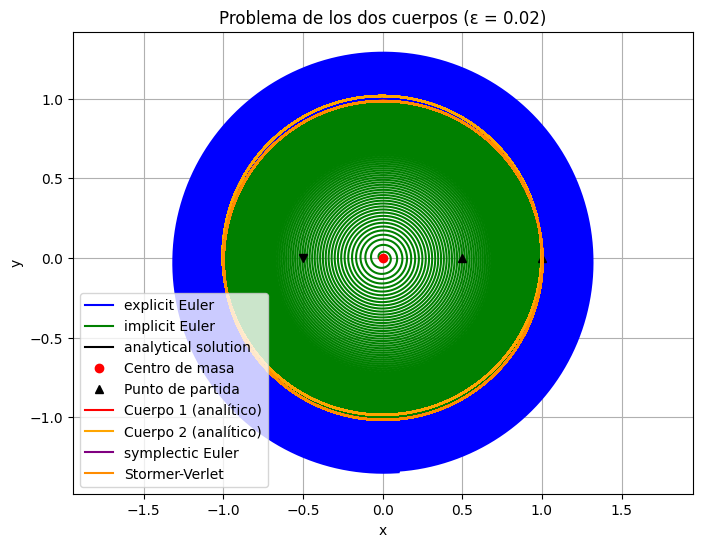

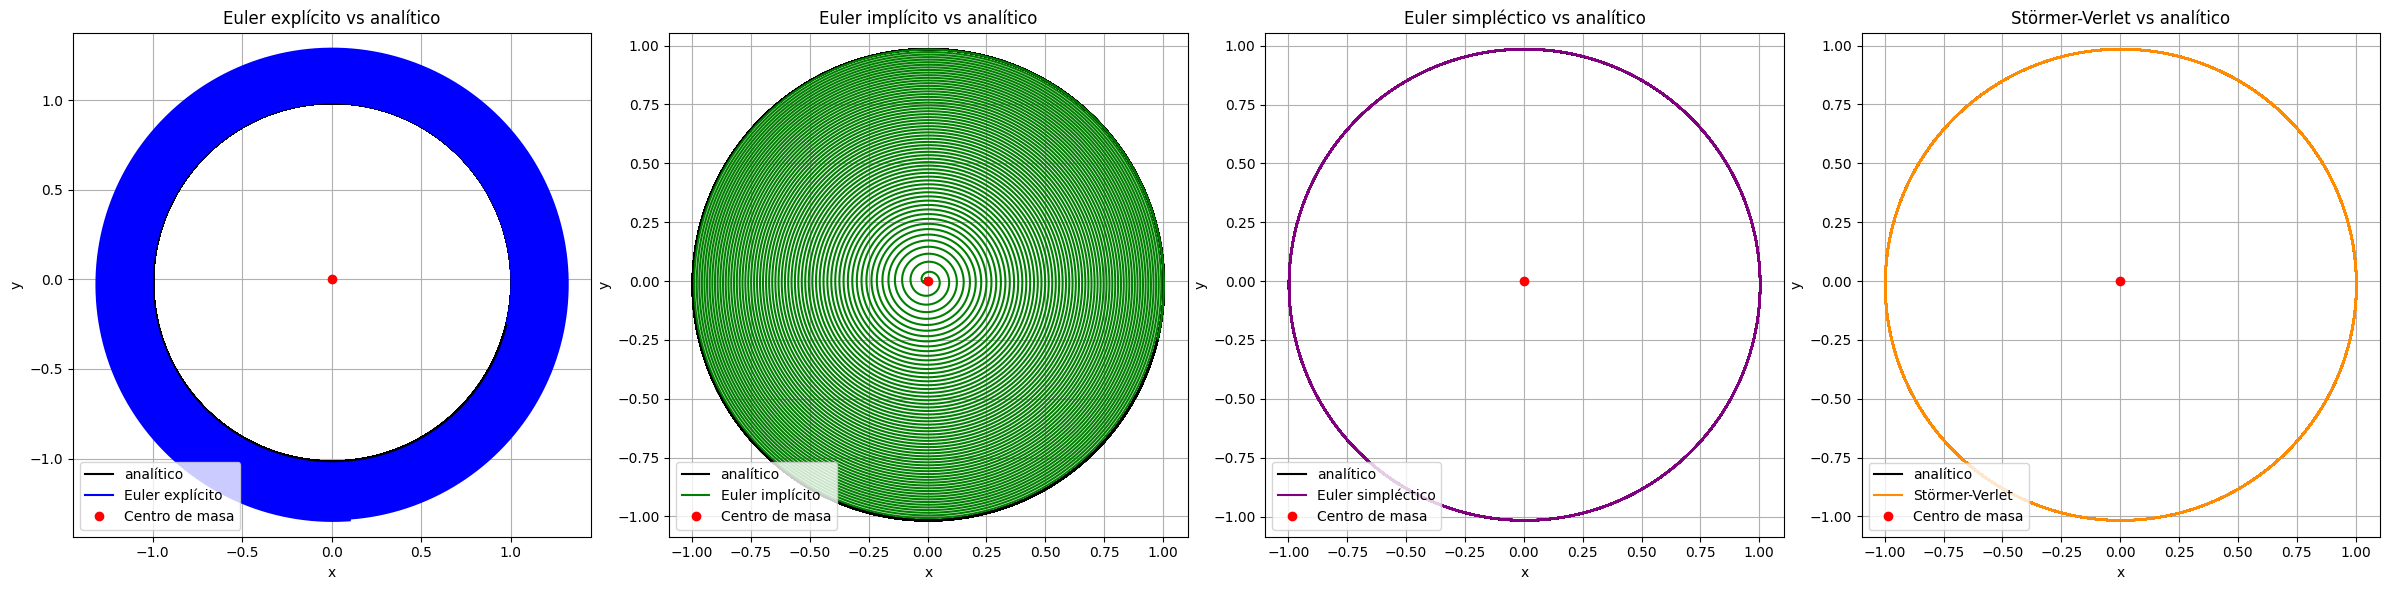

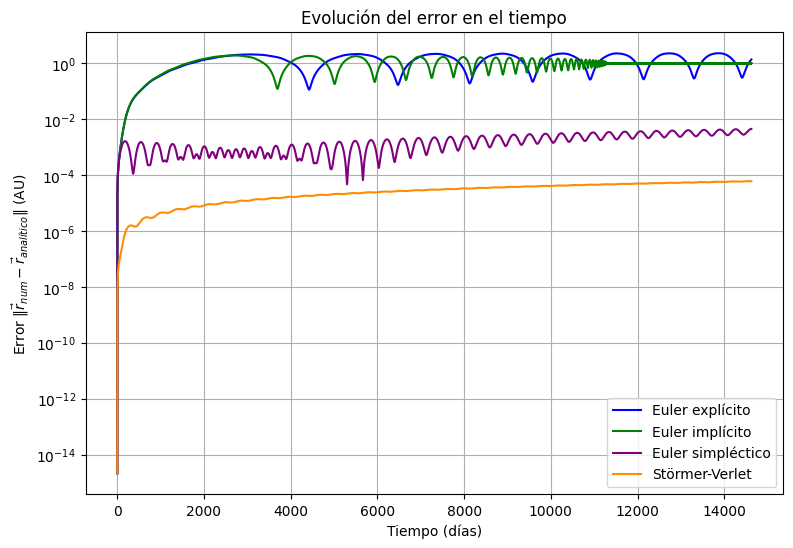

Órbita               Explícito (min/máx)             Implícito (min/máx)           Simpléctico (min/máx)                Verlet (min/máx)
1             2.227e-15        5.275e-02      2.227e-15        5.363e-02      2.227e-15        1.653e-03      2.227e-15        1.607e-06
2             5.276e-02        2.018e-01      5.364e-02        2.107e-01      1.130e-04        1.538e-03      1.455e-06        3.144e-06
3             2.018e-01        4.421e-01      2.107e-01        4.732e-01      2.250e-04        1.423e-03      2.974e-06        4.681e-06
4             4.421e-01        7.609e-01      4.732e-01        8.319e-01      3.037e-04        1.309e-03      4.492e-06        6.218e-06
5             7.610e-01        1.134e+00      8.319e-01        1.253e+00      3.534e-04        1.194e-03      6.010e-06        7.755e-06
6             1.134e+00        1.520e+00      1.253e+00        1.656e+00      3.856e-04        1.079e-03      7.527e-06        9.292e-06
7             1.520e+00        1.857e+00 

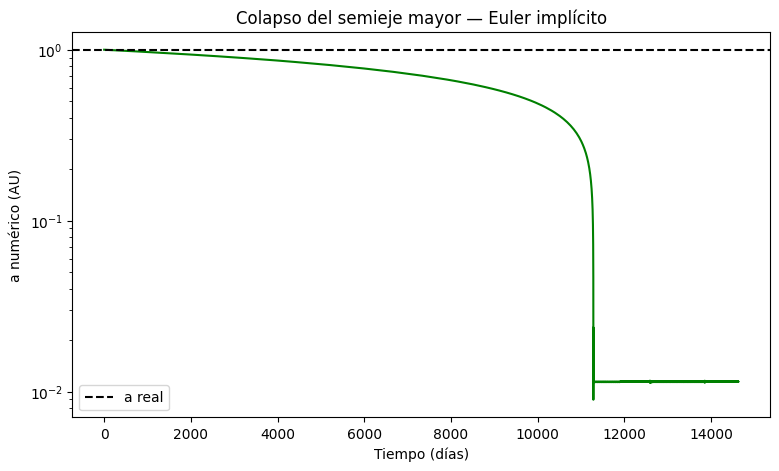

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton, root

#cantidad de orbitas

n_orbitas = 40

#pasos a considerar, notese que entre mayor el paso mejor se notan los cambios,
#en cambio, si usamos pasos muy cortos se extiende el tiempo de compilacion
delta_t = 0.05

# --- Parameters and initial conditions / Parámetros y condiciones iniciales---
G = 2.95912208286e-4   # gravitational constant / constante gravitacional
m1 = 1.0       # masa del sol relativa
m2 = 3.00348959632e-6 # mass de la tierra relativa
M = m1 + m2 # Total mass / Masa total
mu = (m1 * m2) / M

# Start at perihelion on the x-axis / Inicio en el perihelio en el eje x
r0 = np.array([9.773607012272747e-01,-2.440933024736090e-01]) # Initial position / Position initala
v_kreis = np.sqrt(G * M / np.linalg.norm(r0)) # velocity for a circle / velocidad para un circulo
# For a flatter ellipse, use e.g., 1.35 / Para una elipse más plana, usa p.ej. 1.35
v0 = np.array([3.894601620572785e-03, 1.663271328584905e-02])
p0 = v0 * mu

# --- Calculate orbital prameters / Calcular parámetros orbitales ---
r0_norm = np.linalg.norm(r0)
v0_norm = np.linalg.norm(v0)

E_spec = 0.5 * v0_norm**2 - (G * M) / r0_norm # specific energy / energia especifica
a = - (G * M) / (2.0 * E_spec)
h = r0[0]*v0[1] - r0[1]*v0[0] # momentum / momento
epsilon = np.sqrt(1.0 - (h**2) / (G * M * a))

T_orbit = 2.0 * np.pi * np.sqrt(a**3 / (G * M)) #orbital period / periodo orbital
print(T_orbit)
n = np.sqrt(G * M / a**3) # mean motion / movimiento medio

# --- Orientacion y fase de la elipse a partir de r0, v0 (SOLUCION ANALITICA ARREGLADA) ---
# vector de excentricidad: apunta al perihelio
e_vec = (v0_norm**2 / (G * M) - 1.0 / r0_norm) * r0 - (np.dot(r0, v0) / (G * M)) * v0
omega = np.arctan2(e_vec[1], e_vec[0])   # angulo del perihelio

# anomalia verdadera inicial (donde esta la Tierra en t=0)
nu0 = np.arccos(np.clip(np.dot(e_vec, r0) / (np.linalg.norm(e_vec) * r0_norm), -1.0, 1.0))
if np.dot(r0, v0) < 0:          # se acerca al Sol -> segunda mitad de la orbita
    nu0 = 2.0 * np.pi - nu0

# anomalia excentrica y media iniciales
E0 = 2.0 * np.arctan2(np.sqrt(1.0 - epsilon) * np.sin(nu0 / 2), np.sqrt(1.0 + epsilon) * np.cos(nu0 / 2))
M0 = E0 - epsilon * np.sin(E0)

# matriz de rotacion en omega
Rot = np.array([[np.cos(omega), -np.sin(omega)],
                [np.sin(omega),  np.cos(omega)]])

# --- Calculate analytical solution / calcualr solución analitica ---
# evaluate one full orbit t \in [0,T_orbit]
t_eval = np.linspace(0, n_orbitas*T_orbit, n_orbitas*200) #########################################################3
r_analytical = np.zeros((len(t_eval),2))

for i, t in enumerate(t_eval):
    M_anom = M0 + n * t # mean anomaly / anomalia media

    # define Kepler's equation / definir ecuacíon de Kepler: f(E) = E-e*sin(E)-M(t) = 0
    def kepler_eq(E):
        return E - epsilon *np.sin(E) - M_anom
    # Derivatvie of Kepler's equation for faster Newton's method/
    # Derivida para el método de Newton
    def kepler_prime(E):
        return 1.0 - epsilon * np.cos(E)

    # Newton's method (M_anom is a good initial guess) / Método de Newton (M_anom es una buena estimación inicial)
    E_sol = newton(kepler_eq, x0=M_anom, fprime=kepler_prime)

    # Calculate de position in the x,y-plane / Calcular posición en el plano x,y
    x = a * (np.cos(E_sol) - epsilon)
    y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)

    r_analytical[i] = Rot @ np.array([x, y])


# --- Calculate numerical solution using Euler explicit, implicit and symplectic
def grav_force(r):
    r_norm = np.linalg.norm(r)
    return -(G * M * mu) * r / (r_norm**3)

# Explicit Euler

n_steps = int(T_orbit/delta_t)*n_orbitas ###############################################################

r_explicit = np.zeros((n_steps + 1, 2))
p_explicit = np.zeros((n_steps + 1, 2))
r_explicit[0] = r0
p_explicit[0] = p0

for i in range(n_steps):
    r_old = r_explicit[i]
    p_old = p_explicit[i]

    r_explicit[i+1] = r_old + delta_t * (p_old / mu)
    p_explicit[i+1] = p_old + delta_t * grav_force(r_old)

# Implicit Euler

n_steps = n_steps
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    r_guess = r_old + delta_t * (p_old/ mu) #explicit step

    sol = root(residual, r_guess)
    r_next = sol.x

    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i+1] = r_next
    p_implicit[i+1] = p_next

#Euler simplectico


n_steps = int(T_orbit/delta_t)*n_orbitas   ##################################################################

r_symplectic = np.zeros((n_steps + 1, 2))
p_symplectic = np.zeros((n_steps + 1, 2))
r_symplectic[0] = r0
p_symplectic[0] = p0

for i in range(n_steps):
    r_old = r_symplectic[i]
    p_old = p_symplectic[i]

    r_symplectic[i+1] = r_old + delta_t * (p_old / mu)
    p_symplectic[i+1] = p_old + delta_t * grav_force(r_symplectic[i+1])

#Stormer-Verlet

r_verlet = np.zeros((n_steps + 1, 2))
p_verlet = np.zeros((n_steps + 1, 2))
r_verlet[0] = r0
p_verlet[0] = p0

F = grav_force(r0) # fuerza inicial

for i in range(n_steps):
    r_old = r_verlet[i]
    p_old = p_verlet[i]

    p_medio = p_old + 0.5 * delta_t * F              # medio paso de momento
    r_verlet[i+1] = r_old + delta_t * (p_medio / mu)  # paso completo de posicion
    F = grav_force(r_verlet[i+1])                     # fuerza en la posicion nueva (se reutiliza en el siguiente paso)
    p_verlet[i+1] = p_medio + 0.5 * delta_t * F       # otro medio paso de momento

# --- Visualization of the relative vector between the two bodies---
plt.figure(figsize=(8, 6))
plt.plot(r_explicit[:, 0], r_explicit[:, 1], label="explicit Euler", color="blue")
plt.plot(r_implicit[:, 0], r_implicit[:, 1], label="implicit Euler", color="green")
plt.plot(r_analytical[:, 0], r_analytical[:, 1], label="analytical solution", color="black")

plt.plot(0, 0, 'ro', label="Centro de masa")
plt.plot(1, 0, 'k^', label = "Punto de partida")


#Visualizacion de los dos cuerpos:
# Conversión del vector relativo a coordenadas del centro de masa
#r1 = +(m2 / M) * r  und  r2 = -(m1 / M) * r
r1_analytical = (m2 / M) * r_analytical
r2_analytical = -(m1 / M) * r_analytical

# plot of the two bodies
plt.plot(r1_analytical[:, 0], r1_analytical[:, 1], label="Cuerpo 1 (analítico)", color="red")
plt.plot(r2_analytical[:, 0], r2_analytical[:, 1], label="Cuerpo 2 (analítico)", color="orange")
plt.plot(r_symplectic[:, 0], r_symplectic[:, 1], label="symplectic Euler", color="purple")
plt.plot(r_verlet[:, 0], r_verlet[:, 1], label="Stormer-Verlet", color="darkorange")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Problema de los dos cuerpos (ε = {epsilon:.2f})")
plt.axis("equal")
plt.legend(loc='lower left')
plt.grid(True)
plt.plot(0.5, 0, 'k^', label = "Punto de partida")
plt.plot(-0.5, 0, 'kv', label = "Punto de partida")

plt.show()

#Visualización: analítico vs cada método por separado
fig, axs = plt.subplots(1, 4, figsize=(24, 6))

metodos = [
    (r_explicit, "Euler explícito", "blue"),
    (r_implicit, "Euler implícito", "green"),
    (r_symplectic, "Euler simpléctico", "purple"),
    (r_verlet, "Störmer-Verlet", "darkorange"),
]

for ax, (r_num, nombre, color) in zip(axs, metodos):
    ax.plot(r_analytical[:, 0], r_analytical[:, 1], label="analítico", color="black")
    ax.plot(r_num[:, 0], r_num[:, 1], label=nombre, color=color)
    ax.plot(0, 0, 'ro', label="Centro de masa")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"{nombre} vs analítico")
    ax.axis("equal")
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.show()
###################################################################################################################################################################
# ojo: calcula punto a punto y en consecuencia el codigo compila mas lento, solucionamos vectorizando :)
###################################################################################################################################################################

#t_sync = np.arange(n_steps + 1) * delta_t   # mismos instantes que usa tu loop: t_i = i*delta_t
# r_analytical_sync = np.zeros((n_steps + 1, 2))

# for i, t in enumerate(t_sync):
#     M_anom = n * t
#     E_sol = newton(lambda E: E - epsilon*np.sin(E) - M_anom,
#                     x0=M_anom,
#                     fprime=lambda E: 1.0 - epsilon*np.cos(E))
#     x = a * (np.cos(E_sol) - epsilon)
#     y = a * np.sqrt(1.0 - epsilon**2) * np.sin(E_sol)
#     r_analytical_sync[i] = [x, y]

###################################################################################################################################################################



#creamos arreglos a vectorizar


t_sync = np.arange(n_steps + 1) * delta_t
M_anom = M0 + n * t_sync

# Newton-Raphson vectorizado: itera sobre TODO el arreglo a la vez
E = M_anom.copy()                      # estimación inicial
for _ in range(6):
    E = E - (E - epsilon*np.sin(E) - M_anom) / (1.0 - epsilon*np.cos(E))

r_analytical_sync = np.column_stack([
    a * (np.cos(E) - epsilon),
    a * np.sqrt(1.0 - epsilon**2) * np.sin(E)
]) @ Rot.T


#Error por metodo

error_explicit  = np.linalg.norm(r_explicit  - r_analytical_sync, axis=1)
error_implicit  = np.linalg.norm(r_implicit  - r_analytical_sync, axis=1)
error_symplectic = np.linalg.norm(r_symplectic - r_analytical_sync, axis=1)
error_verlet = np.linalg.norm(r_verlet - r_analytical_sync, axis=1)


plt.figure(figsize=(9, 6))
plt.plot(t_sync, error_explicit, label="Euler explícito", color="blue")
plt.plot(t_sync, error_implicit, label="Euler implícito", color="green")
plt.plot(t_sync, error_symplectic, label="Euler simpléctico", color="purple")
plt.plot(t_sync, error_verlet, label="Störmer-Verlet", color="darkorange")
plt.xlabel("Tiempo (días)")
plt.ylabel(r"Error $\|\vec r_{num} - \vec r_{analítico}\|$ (AU)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both")
plt.title("Evolución del error en el tiempo")
plt.show()


# --- Resumen numérico del error, órbita por órbita ---
pasos_por_orbita = int(T_orbit / delta_t)

print(f"{'Órbita':<8}{'Explícito (min/máx)':>32}{'Implícito (min/máx)':>32}{'Simpléctico (min/máx)':>32}{'Verlet (min/máx)':>32}")
for k in range(n_orbitas):
    ini = k * pasos_por_orbita
    fin = (k + 1) * pasos_por_orbita

    tramo_exp = error_explicit[ini:fin]
    tramo_imp = error_implicit[ini:fin]
    tramo_sym = error_symplectic[ini:fin]
    tramo_ver = error_verlet[ini:fin]

    print(f"{k+1:<8}"
          f"{tramo_exp.min():>15.3e}{tramo_exp.max():>17.3e}"
          f"{tramo_imp.min():>15.3e}{tramo_imp.max():>17.3e}"
          f"{tramo_sym.min():>15.3e}{tramo_sym.max():>17.3e}"
          f"{tramo_ver.min():>15.3e}{tramo_ver.max():>17.3e}")

#como, teoricamente, sabemos que el euler implicito va a ser mala aproximacion hacia el interior de la elipse,
#podemos observar el comportamiento para distintas cantidades de orbitas en un determinado paso

    v_implicit = p_implicit / mu
E_spec_num = 0.5*np.linalg.norm(v_implicit, axis=1)**2 - G*M/np.linalg.norm(r_implicit, axis=1)
a_num_implicit = -G*M/(2.0*E_spec_num)

plt.figure(figsize=(9,5))
plt.plot(t_sync, a_num_implicit, color="green")
plt.axhline(a, color="black", linestyle="--", label="a real")
plt.xlabel("Tiempo (días)")
plt.ylabel("a numérico (AU)")
plt.yscale("log")
plt.legend()
plt.title("Colapso del semieje mayor — Euler implícito")
plt.show()

EULER IMPLÍCITO MEJORADO: NEWTON PROPIO (JACOBIANO ANALÍTICO) VS SPICY.OPTIMIZE.ROOT


*Descartado por resultados no reales, se mantiene spicy.optimize.root*

In [ ]:
#--IMPLICIT-EULER-IMPROOVED--########################################
# --- 1. Newton-Raphson-Schritt mit analytischer Jacobi-Matrix ---
def solve_implicit_step_2d(r_old, p_old, delta_t, mu, GM, tol=1e-12, max_iter=20):
    k = delta_t**2 * GM
    c = r_old + (delta_t / mu) * p_old  # Konstanter Vektor c_n

    # Startschätzung (expliziter Euler-Schritt)
    r = c.copy()

    for _ in range(max_iter):
        r_sq = np.dot(r, r)
        r_norm = np.sqrt(r_sq)
        r3 = r_norm**3
        r5 = r_norm**5

        # Residuum: g(r) = r + (k / ||r||^3) * r - c
        g = r + (k / r3) * r - c
        if np.linalg.norm(g) < tol:
            break

        # Analytische 2x2-Jacobi-Matrix
        diag_base = 1.0 + k / r3
        j11 = diag_base - 3.0 * k * (r[0]**2) / r5
        j22 = diag_base - 3.0 * k * (r[1]**2) / r5
        j12 = -3.0 * k * (r[0] * r[1]) / r5

        J = np.array([
            [j11, j12],
            [j12, j22]
        ])

        # 2x2 lineares Gleichungssystem lösen: J * delta_r = g
        delta_r = np.linalg.solve(J, g)
        r -= delta_r

        if np.linalg.norm(delta_r) < tol:
            break

    return r


In [ ]:
%%timeit -n 1 -r 3
# Implicit Euler

n_steps = 146260*2 # 40 ortbits!!
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    r_guess = r_old + delta_t * (p_old/ mu) #explicit step

    sol = root(residual, r_guess, tol=1e-12)
    r_next = sol.x

    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i+1] = r_next
    p_implicit[i+1] = p_next

47.2 s ± 1.18 s per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [ ]:
%%timeit -n 1 -r 3

n_steps = 146260*2 # 40 orbits
r_implicit = np.zeros((n_steps + 1, 2))
p_implicit = np.zeros((n_steps + 1, 2))
r_implicit[0] = r0
p_implicit[0] = p0

for i in range(n_steps):
    r_old = r_implicit[i]
    p_old = p_implicit[i]

    # Ort über eigenen 2D-Newton-Schritt berechnen
    r_next = solve_implicit_step_2d(r_old, p_old, delta_t, mu, G * M)

    # Impuls direkt nachziehen
    p_next = p_old + delta_t * grav_force(r_next)

    r_implicit[i + 1] = r_next
    p_implicit[i + 1] = p_next

14.5 s ± 53.1 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


improved implicit Euler implementation needs 58 % less time calculating 20 orbits (7s vs 17s)
and 68 % less time calculating 40 orbits (12s vs 38s) compared to the original implementation!!

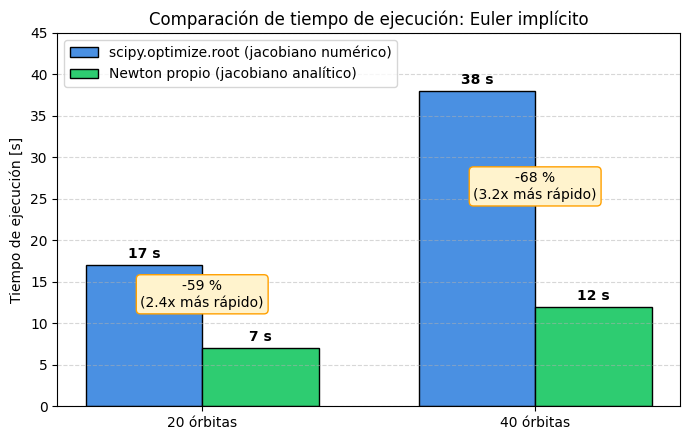

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

órbitas = ['20 órbitas', '40 órbitas']
t_scipy = [17, 38]
t_custom = [7, 12]

x = np.arange(len(órbitas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=100)
barras1 = ax.bar(x - ancho/2, t_scipy, ancho, label='scipy.optimize.root (jacobiano numérico)', color='#4A90E2', edgecolor='black')
barras2 = ax.bar(x + ancho/2, t_custom, ancho, label='Newton propio (jacobiano analítico)', color='#2ECC71', edgecolor='black')

# Etiquetas sobre las barras
ax.bar_label(barras1, padding=3, fmt='%d s', fontweight='bold')
ax.bar_label(barras2, padding=3, fmt='%d s', fontweight='bold')

# Anotaciones de mejora / reducción de tiempo
ax.annotate('-59 %\n(2.4x más rápido)', xy=(0, 12), ha='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3CD', edgecolor='#FFA000'))
ax.annotate('-68 %\n(3.2x más rápido)', xy=(1, 25), ha='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3CD', edgecolor='#FFA000'))

ax.set_ylabel('Tiempo de ejecución [s]')
ax.set_title('Comparación de tiempo de ejecución: Euler implícito')
ax.set_xticks(x)
ax.set_xticklabels(órbitas)
ax.set_ylim(0, 45)
ax.legend(loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("benchmark_euler.png", dpi=300)
plt.show()




Verificación si la optimización cumple



R* = 0.0114 AU,  C_min = 0.0171 AU
scipy.root:   pasos sin solucion (C < C_min) = 66842,  pasos con sol.success = False: 67246
Newton propio: pasos sin solucion (C < C_min) = 3,  pasos con residuo > 1e-8: 3
Newton propio: primer paso sin solucion en t = 30.89 años, |r| = 0.0170 AU
scipy.root:    primer paso sin solucion en t = 30.89 años, |r| = 0.0170 AU
Distancia final: scipy.root = 0.0114 AU,  Newton propio = 1370664.6 AU


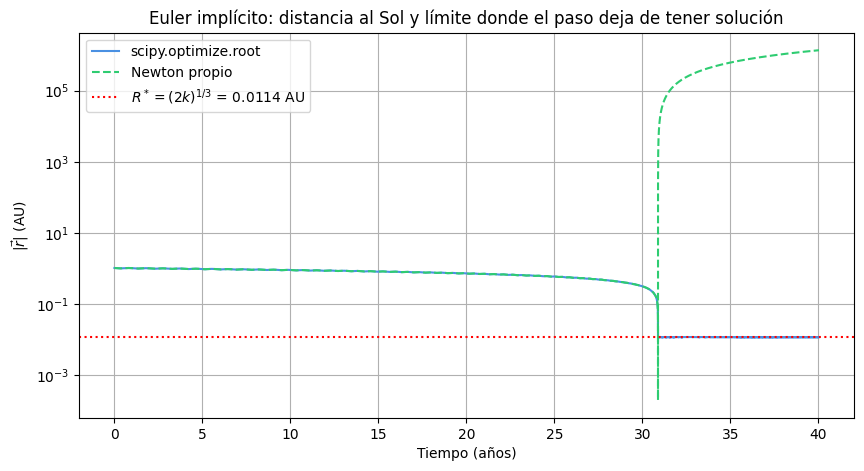

In [ ]:
# --- Verificacion: ¿el paso implicito tiene solucion? ---
# Reemplazando v_{n+1} en r_{n+1}, el paso implicito queda  r_{n+1} (1 + k/|r_{n+1}|^3) = c,
# con k = delta_t^2 G M  y  c = r_n + delta_t v_n.  Tomando normas (R = |r_{n+1}|, C = |c|):
#       R + k/R^2 = C
# f(R) = R + k/R^2 tiene un minimo en R* = (2k)^(1/3), donde vale C_min = 3 k^(1/3) / 2^(2/3).
# Si C < C_min la ecuacion NO tiene solucion real: ningun metodo puede encontrar r_{n+1}.

k = delta_t**2 * G * M
R_estrella = (2 * k)**(1 / 3)
C_min = 3 * k**(1 / 3) / 2**(2 / 3)
print(f"R* = {R_estrella:.4f} AU,  C_min = {C_min:.4f} AU")

n_steps = 146260*2 # 40 orbits (igual que en el timeit)

r_scipy = np.zeros((n_steps + 1, 2))
p_scipy = np.zeros((n_steps + 1, 2))
r_newton = np.zeros((n_steps + 1, 2))
p_newton = np.zeros((n_steps + 1, 2))
r_scipy[0], p_scipy[0] = r0, p0
r_newton[0], p_newton[0] = r0, p0

C_scipy = np.zeros(n_steps)       # C = |r_n + delta_t v_n| en cada paso
C_newton = np.zeros(n_steps)
exito_scipy = np.zeros(n_steps, dtype=bool)   # sol.success de root
residuo_newton = np.zeros(n_steps)            # |g(r_{n+1})| que deja el Newton propio

for i in range(n_steps):
    # scipy.optimize.root
    r_old = r_scipy[i]
    p_old = p_scipy[i]
    C_scipy[i] = np.linalg.norm(r_old + (delta_t / mu) * p_old)

    def residual(r_next):
        return r_next - r_old - (delta_t / mu) * p_old - (delta_t**2 / mu) * grav_force(r_next)

    sol = root(residual, r_old + delta_t * (p_old / mu), tol=1e-12)
    exito_scipy[i] = sol.success
    r_scipy[i + 1] = sol.x
    p_scipy[i + 1] = p_old + delta_t * grav_force(sol.x)

    # Newton propio
    r_old = r_newton[i]
    p_old = p_newton[i]
    c = r_old + (delta_t / mu) * p_old
    C_newton[i] = np.linalg.norm(c)

    r_next = solve_implicit_step_2d(r_old, p_old, delta_t, mu, G * M)
    residuo_newton[i] = np.linalg.norm(r_next + (k / np.linalg.norm(r_next)**3) * r_next - c)
    r_newton[i + 1] = r_next
    p_newton[i + 1] = p_old + delta_t * grav_force(r_next)

t_steps = np.arange(n_steps + 1) * delta_t / 365.25   # tiempo en años
sin_sol_scipy = np.where(C_scipy < C_min)[0]
sin_sol_newton = np.where(C_newton < C_min)[0]

print(f"scipy.root:   pasos sin solucion (C < C_min) = {len(sin_sol_scipy)},  pasos con sol.success = False: {np.sum(~exito_scipy)}")
print(f"Newton propio: pasos sin solucion (C < C_min) = {len(sin_sol_newton)},  pasos con residuo > 1e-8: {np.sum(residuo_newton > 1e-8)}")
if len(sin_sol_newton) > 0:
    i0 = sin_sol_newton[0]
    print(f"Newton propio: primer paso sin solucion en t = {t_steps[i0]:.2f} años, |r| = {np.linalg.norm(r_newton[i0]):.4f} AU")
if len(sin_sol_scipy) > 0:
    i0 = sin_sol_scipy[0]
    print(f"scipy.root:    primer paso sin solucion en t = {t_steps[i0]:.2f} años, |r| = {np.linalg.norm(r_scipy[i0]):.4f} AU")

print(f"Distancia final: scipy.root = {np.linalg.norm(r_scipy[-1]):.4f} AU,  Newton propio = {np.linalg.norm(r_newton[-1]):.1f} AU")

plt.figure(figsize=(10, 5))
plt.plot(t_steps, np.linalg.norm(r_scipy, axis=1), label="scipy.optimize.root", color="#4A90E2")
plt.plot(t_steps, np.linalg.norm(r_newton, axis=1), label="Newton propio", color="#2ECC71", ls="--")
plt.axhline(R_estrella, color="red", ls=":", label=rf"$R^* = (2k)^{{1/3}}$ = {R_estrella:.4f} AU")
plt.yscale("log")
plt.xlabel("Tiempo (años)")
plt.ylabel(r"$|\vec r|$ (AU)")
plt.title("Euler implícito: distancia al Sol y límite donde el paso deja de tener solución")
plt.grid(True, which="both")
plt.legend()
plt.show()

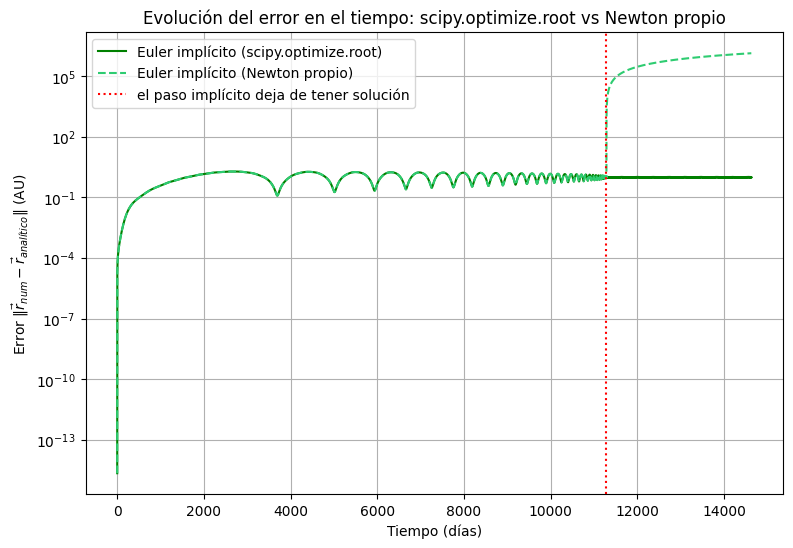

In [ ]:
# --- Error contra la analitica: Euler implicito con scipy.optimize.root vs Newton propio ---
# Usa r_scipy, r_newton, t_steps y sin_sol_scipy de la celda de verificacion.

t_sync_impl = np.arange(n_steps + 1) * delta_t
M_anom = M0 + n * t_sync_impl

# Newton-Raphson vectorizado para la ecuacion de Kepler (igual que en la simulacion)
E = M_anom.copy()
for _ in range(6):
    E = E - (E - epsilon*np.sin(E) - M_anom) / (1.0 - epsilon*np.cos(E))

r_analytical_impl = np.column_stack([
    a * (np.cos(E) - epsilon),
    a * np.sqrt(1.0 - epsilon**2) * np.sin(E)
]) @ Rot.T

error_scipy = np.linalg.norm(r_scipy - r_analytical_impl, axis=1)
error_newton = np.linalg.norm(r_newton - r_analytical_impl, axis=1)

plt.figure(figsize=(9, 6))
plt.plot(t_sync_impl, error_scipy, label="Euler implícito (scipy.optimize.root)", color="green")
plt.plot(t_sync_impl, error_newton, label="Euler implícito (Newton propio)", color="#2ECC71", ls="--")
if len(sin_sol_scipy) > 0:
    plt.axvline(t_sync_impl[sin_sol_scipy[0]], color="red", ls=":", label="el paso implícito deja de tener solución")
plt.xlabel("Tiempo (días)")
plt.ylabel(r"Error $\|\vec r_{num} - \vec r_{analítico}\|$ (AU)")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both")
plt.title("Evolución del error en el tiempo: scipy.optimize.root vs Newton propio")
plt.show()

SIMULACIÓN DEL SISTEMA SOLAR CON STÖRMER-VERLET

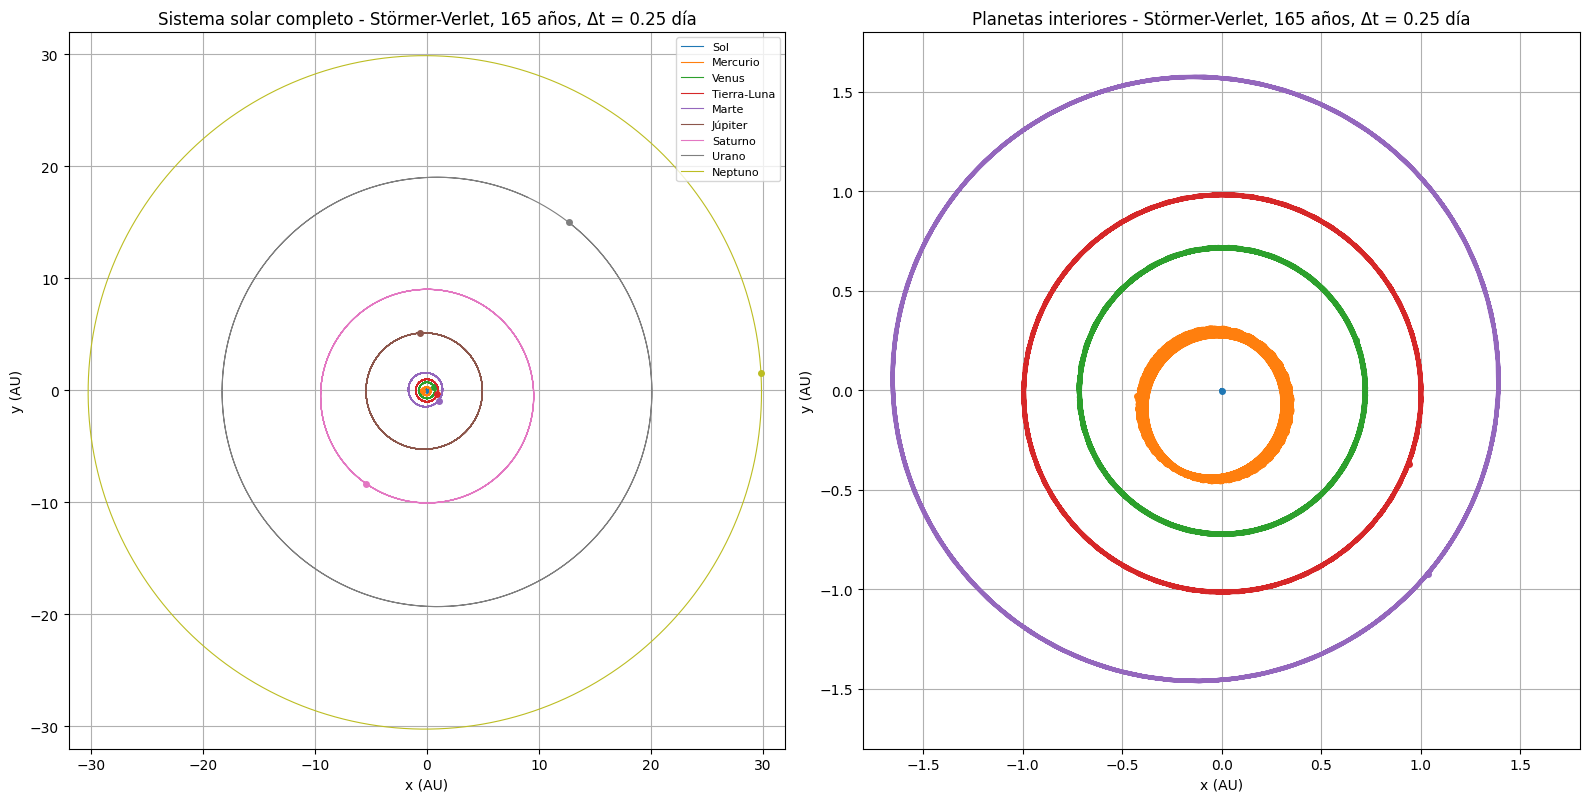

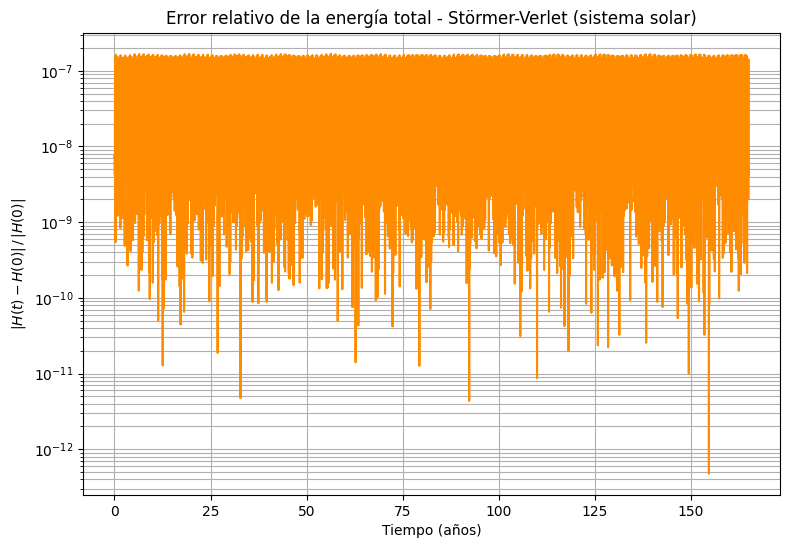

Pasos: 241065,  error relativo maximo de energia: 1.68e-07


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parametros de la simulacion ---
n_anios = 165        # años simulados (165 ≈ una vuelta de Neptuno)
delta_t = 0.25       # paso en dias (lo fija Mercurio, que orbita en 88 dias)
guardar_cada = 40    # se guarda 1 de cada 40 pasos (cada 10 dias) para no llenar la memoria

# --- Condiciones iniciales: JPL Horizons (DE441), 2026-09-09 00:00 TDB ---
# Centro: baricentro del sistema solar (500@0), ecliptica J2000, AU y AU/dia.
# Planetas = baricentro de cada sistema (planeta + lunas).
nombres = ["Sol", "Mercurio", "Venus", "Tierra-Luna", "Marte",
           "Júpiter", "Saturno", "Urano", "Neptuno"]

r0 = np.array([
    [-1.379568080257273E-03, -5.193747185412778E-03,  9.749477393201387E-05],  # Sol
    [-3.875567685649621E-01, -1.722418553987977E-01,  2.186444932045817E-02],  # Mercurio
    [ 5.441765559316214E-01, -4.860101172059397E-01, -3.798636112407187E-02],  # Venus
    [ 9.759587490149243E-01, -2.492669709268985E-01,  1.063029195410369E-04],  # Tierra-Luna
    [ 4.166932708403255E-01,  1.466804765677485E+00,  2.069395609077339E-02],  # Marte
    [-3.363086681349439E+00,  4.091502536449919E+00,  5.829340769016911E-02],  # Jupiter
    [ 9.286797617596529E+00,  1.641111025015846E+00, -3.982996673622751E-01],  # Saturno
    [ 9.006900862945637E+00,  1.722751177210032E+01, -5.270509903817747E-02],  # Urano
    [ 2.983987559187763E+01,  1.305612573086189E+00, -7.145772572513928E-01],  # Neptuno
])
v0 = np.array([
    [ 6.138069622840418E-06,  2.349477251906276E-06, -1.288121364640814E-07],  # Sol
    [ 5.362034326165775E-03, -2.460056093556392E-02, -2.502002721731356E-03],  # Mercurio
    [ 1.325013718903194E-02,  1.509944295510669E-02, -5.568701287262392E-04],  # Venus
    [ 3.895648296064459E-03,  1.662964341190581E-02, -1.153858021748374E-06],  # Tierra-Luna
    [-1.292456616204334E-02,  5.015092642929407E-03,  4.219854485301565E-04],  # Marte
    [-5.920013611396425E-03, -4.436284497829372E-03,  1.509002270139405E-04],  # Jupiter
    [-1.277138973284334E-03,  5.481588739745702E-03, -4.448399038122698E-05],  # Saturno
    [-3.514473895474114E-03,  1.638959609773887E-03,  5.161428245760983E-05],  # Urano
    [-1.578592253880974E-04,  3.154748571525165E-03, -6.132894511182756E-05],  # Neptuno
])

# masas en masas solares (inversa de la razon de masas IAU)
m = 1.0 / np.array([1.0, 6023600.0, 408523.71, 328900.56, 3098708.0,
                    1047.3486, 3497.898, 22902.98, 19412.24])
G = 2.95912208286e-4   # AU^3 / dia^2 / M_sol
N = len(m)

# --- Fuerza gravitacional sobre cada cuerpo (suma sobre todos los pares) ---
# F_i = sum_{j != i} G m_i m_j (r_j - r_i) / |r_j - r_i|^3
def grav_force_N(r):
    dif = r[np.newaxis, :, :] - r[:, np.newaxis, :]          # dif[i, j] = r_j - r_i
    dist3 = (np.sum(dif**2, axis=2) + np.eye(N))**1.5          # +eye evita dividir por 0 en i = j (ahi dif = 0)
    return G * m[:, None] * np.sum(m[None, :, None] * dif / dist3[:, :, None], axis=1)

# --- Energia total: cinetica - potencial (sobre cada par una vez) ---
def energia_total(r, p):
    cinetica = np.sum(np.sum(p**2, axis=1) / (2 * m))
    potencial = 0.0
    for i in range(N):
        for j in range(i + 1, N):
            potencial -= G * m[i] * m[j] / np.linalg.norm(r[i] - r[j])
    return cinetica + potencial

#Stormer-Verlet para N cuerpos (igual que en N = 2, pero r y p son matrices N x 3)

n_steps = int(n_anios * 365.25 / delta_t)
n_guardados = n_steps // guardar_cada + 1

r_verlet_N = np.zeros((n_guardados, N, 3))
p_verlet_N = np.zeros((n_guardados, N, 3))
t_guardado = np.zeros(n_guardados)

r = r0.copy()
p = m[:, None] * v0            # momento de cada cuerpo: p_i = m_i v_i
r_verlet_N[0], p_verlet_N[0] = r, p

F = grav_force_N(r) # fuerza inicial

for i in range(n_steps):
    p_medio = p + 0.5 * delta_t * F                # medio paso de momento
    r = r + delta_t * p_medio / m[:, None]          # paso completo de posicion
    F = grav_force_N(r)                             # fuerza en la posicion nueva (se reutiliza en el siguiente paso)
    p = p_medio + 0.5 * delta_t * F                 # otro medio paso de momento

    if (i + 1) % guardar_cada == 0:
        k = (i + 1) // guardar_cada
        r_verlet_N[k], p_verlet_N[k] = r, p
        t_guardado[k] = (i + 1) * delta_t

# --- Visualizacion de las orbitas ---
fig, axs = plt.subplots(1, 2, figsize=(16, 8))
for ax, limite, titulo in [(axs[0], 32, "Sistema solar completo"),
                           (axs[1], 1.8, "Planetas interiores")]:
    for k in range(N):
        ax.plot(r_verlet_N[:, k, 0], r_verlet_N[:, k, 1], lw=0.8, label=nombres[k])
        ax.plot(r_verlet_N[-1, k, 0], r_verlet_N[-1, k, 1], 'o', ms=4, color=ax.lines[-1].get_color())
    ax.set_xlim(-limite, limite); ax.set_ylim(-limite, limite)
    ax.set_aspect("equal")
    ax.set_xlabel("x (AU)"); ax.set_ylabel("y (AU)")
    ax.set_title(f"{titulo} - Störmer-Verlet, {n_anios} años, Δt = {delta_t} día")
    ax.grid(True)
axs[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# --- Conservacion de la energia (no hay solucion analitica para N > 2) ---
H = np.array([energia_total(r_verlet_N[k], p_verlet_N[k]) for k in range(n_guardados)])
error_H = np.abs((H - H[0]) / H[0])

plt.figure(figsize=(9, 6))
plt.plot(t_guardado[1:] / 365.25, error_H[1:], color="darkorange")
plt.xlabel("Tiempo (años)")
plt.ylabel(r"$|H(t) - H(0)| \,/\, |H(0)|$")
plt.yscale("log")
plt.grid(True, which="both")
plt.title("Error relativo de la energía total - Störmer-Verlet (sistema solar)")
plt.show()

print(f"Pasos: {n_steps},  error relativo maximo de energia: {error_H.max():.2e}")


LOG ERROR DEL SISTEMA SOLAR

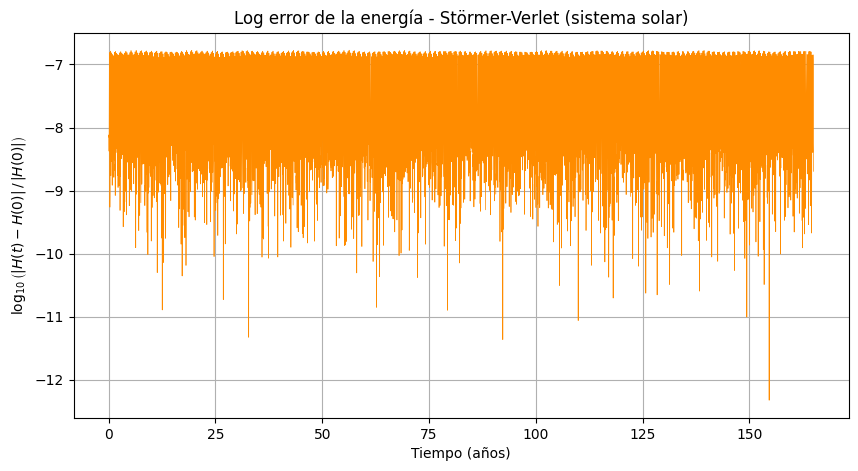

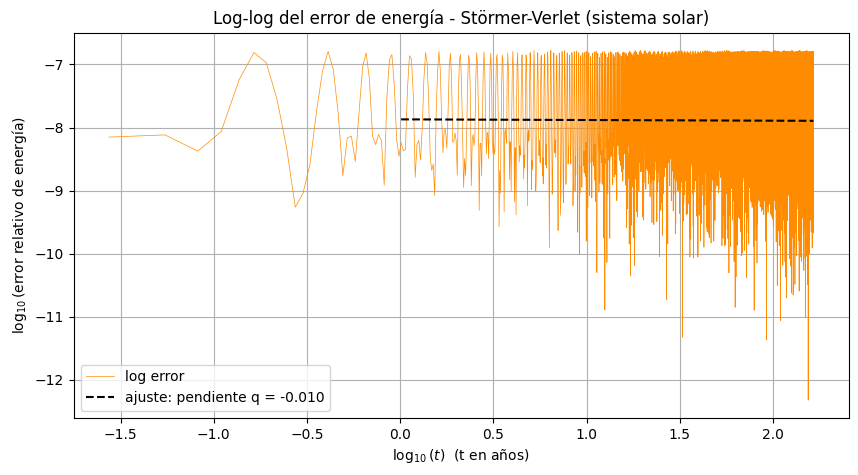

log10 del error: mínimo -12.32, máximo -6.77
pendiente en log-log: q = -0.010


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Log error del sistema solar ---
# Usa el error relativo de energia del bloque anterior (error_H, t_guardado).
# log10(error) dice el orden de magnitud del error: -7 significa ~1e-7.

t_anios = t_guardado[1:] / 365.25        # se omite t = 0 (error 0, log10 no definido)
log_error = np.log10(error_H[1:])

# 1) log10(error) en el tiempo
plt.figure(figsize=(10, 5))
plt.plot(t_anios, log_error, color="darkorange", lw=0.5)
plt.xlabel("Tiempo (años)")
plt.ylabel(r"$\log_{10}\left(|H(t) - H(0)| \,/\, |H(0)|\right)$")
plt.title("Log error de la energía - Störmer-Verlet (sistema solar)")
plt.grid(True)
plt.show()

# 2) log-log: log10(error) vs log10(t)
# Si error ~ C t^q, entonces log10(error) = log10(C) + q log10(t): la pendiente q dice como crece el error.
#   q ~ 0 -> error acotado (no crece),  q ~ 1 -> crece lineal,  q ~ 2 -> crece cuadratico
log_t = np.log10(t_anios)
desde = t_anios >= 1.0                   # se ajusta desde 1 año, cuando ya pasaron varias orbitas
q, logC = np.polyfit(log_t[desde], log_error[desde], 1)

plt.figure(figsize=(10, 5))
plt.plot(log_t, log_error, color="darkorange", lw=0.5, label="log error")
plt.plot(log_t[desde], logC + q * log_t[desde], "k--", label=f"ajuste: pendiente q = {q:.3f}")
plt.xlabel(r"$\log_{10}(t)$  (t en años)")
plt.ylabel(r"$\log_{10}$(error relativo de energía)")
plt.title("Log-log del error de energía - Störmer-Verlet (sistema solar)")
plt.grid(True)
plt.legend()
plt.show()

print(f"log10 del error: mínimo {log_error.min():.2f}, máximo {log_error.max():.2f}")
print(f"pendiente en log-log: q = {q:.3f}")


ERROR DE POSICIÓN DEL SISTEMA SOLAR CONTRA JPL HORIZONS

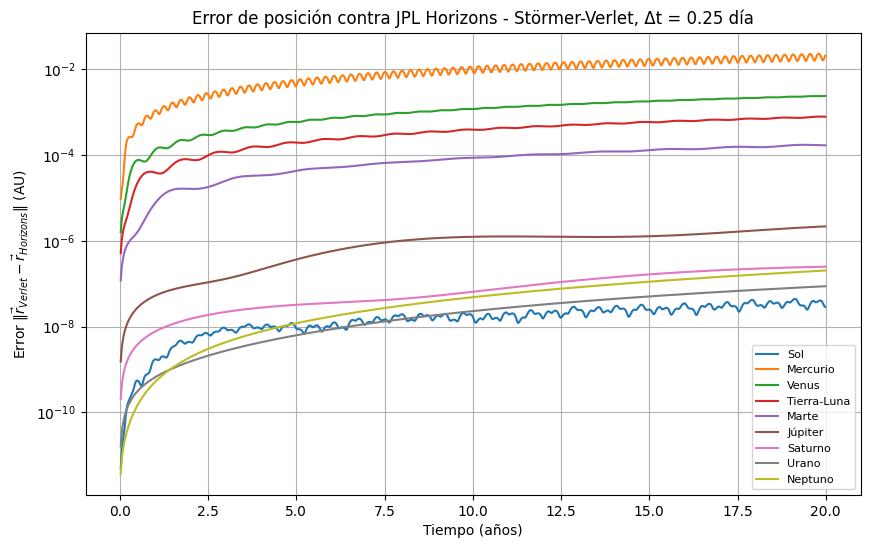

Cuerpo                1 años        5 años       10 años       20 años
Sol                1.729e-09     8.788e-09     1.742e-08     2.867e-08
Mercurio           1.092e-03     4.181e-03     9.533e-03     2.049e-02
Venus              1.341e-04     5.784e-04     1.161e-03     2.348e-03
Tierra-Luna        3.830e-05     1.925e-04     3.859e-04     7.719e-04
Marte              7.722e-06     4.259e-05     8.560e-05     1.662e-04
Júpiter            5.288e-08     3.672e-07     1.235e-06     2.154e-06
Saturno            7.758e-09     3.216e-08     6.470e-08     2.481e-07
Urano              6.706e-10     6.305e-09     2.294e-08     8.706e-08
Neptuno            5.257e-10     1.201e-08     4.832e-08     2.022e-07


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import requests
from datetime import date, timedelta

# --- Error de posicion contra JPL Horizons ---
# Usa la simulacion del bloque anterior (r_verlet_N, delta_t, guardar_cada, nombres).
# Horizons hace el papel de la solucion analitica: da la posicion real de cada cuerpo en cada fecha.

anios_error = 20                          # años a comparar (no mas que n_anios)
paso_dias = delta_t * guardar_cada        # 10 dias: mismo espaciado que los puntos guardados
assert anios_error <= n_anios, "anios_error no puede ser mayor que n_anios"
assert paso_dias == int(paso_dias), "delta_t * guardar_cada tiene que ser un numero entero de dias"
paso_dias = int(paso_dias)

ids_horizons = ['10', '1', '2', '3', '4', '5', '6', '7', '8']   # mismo orden que nombres
fecha_inicio = date(2026, 9, 9)                                  # misma epoca que las condiciones iniciales
fecha_fin = fecha_inicio + timedelta(days=int(anios_error * 365.25 / paso_dias) * paso_dias)

def descargar_horizons(id_cuerpo):
    # misma consulta que las condiciones iniciales, pero cada paso_dias y solo posiciones
    params = {
        "format": "text", "COMMAND": f"'{id_cuerpo}'", "OBJ_DATA": "'NO'",
        "EPHEM_TYPE": "'VECTORS'", "CENTER": "'500@0'", "REF_PLANE": "'ECLIPTIC'",
        "START_TIME": f"'{fecha_inicio}'", "STOP_TIME": f"'{fecha_fin}'",
        "STEP_SIZE": f"'{paso_dias}d'", "OUT_UNITS": "'AU-D'",
        "VEC_TABLE": "'1'", "CSV_FORMAT": "'YES'",
    }
    texto = requests.get("https://ssd.jpl.nasa.gov/api/horizons.api", params=params).text
    # las filas de datos estan entre $$SOE y $$EOE: JD, fecha, X, Y, Z,
    filas = texto[texto.index("$$SOE") + 5 : texto.index("$$EOE")].strip().split("\n")
    return np.array([[float(c) for c in fila.split(",")[2:5]] for fila in filas])

r_horizons = np.array([descargar_horizons(id_c) for id_c in ids_horizons])   # (cuerpos, fechas, 3)
r_horizons = r_horizons.transpose(1, 0, 2)                                  # (fechas, cuerpos, 3), igual que r_verlet_N

n_fechas = min(len(r_horizons), len(r_verlet_N))
t_anios = np.arange(n_fechas) * paso_dias / 365.25

# error(t) = || r_verlet(t) - r_horizons(t) ||  para cada cuerpo, en las mismas fechas
error_horizons = np.linalg.norm(r_verlet_N[:n_fechas] - r_horizons[:n_fechas], axis=2)

plt.figure(figsize=(10, 6))
for k in range(len(nombres)):
    plt.plot(t_anios[1:], error_horizons[1:, k], label=nombres[k])     # t=0 tiene error ~0 (log no lo dibuja)
plt.yscale("log")
plt.xlabel("Tiempo (años)")
plt.ylabel(r"Error $\|\vec r_{Verlet} - \vec r_{Horizons}\|$ (AU)")
plt.title(f"Error de posición contra JPL Horizons - Störmer-Verlet, Δt = {delta_t} día")
plt.grid(True, which="both")
plt.legend(loc="lower right", fontsize=8)
plt.show()

# --- Resumen numerico: error en algunas fechas ---
anios_tabla = [1, 5, 10, anios_error]
print(f"{'Cuerpo':<14}" + "".join(f"{f'{a} años':>14}" for a in anios_tabla))
for k in range(len(nombres)):
    fila = f"{nombres[k]:<14}"
    for a in anios_tabla:
        i = min(int(round(a * 365.25 / paso_dias)), n_fechas - 1)
        fila += f"{error_horizons[i, k]:>14.3e}"
    print(fila)
